This notebook runs under semantic conda env on IMac

# Reconstruction of time-varying MPS from PCA: log MPS vs raw MPS
The PCAs fitted and saved by 8_Obtain_timeVaryingAcousticFeatureSpace.ipynb (500 PCs each) are used to project every vocalization of the library and reconstruct its time-varying MPS (tMPS) from the first k PCs, k = 20, 50, 100, 200, 500.
- **log PCA**: fitted on the log MPS (`pca_tmps_log_500PCs.h5`)
- **raw PCA**: fitted on the MPS in power (`pca_tmps_raw_500PCs.h5`)

Both reconstructions are compared with the original in dB, using the same pre-processing as the log PCA: 10*log10, minus `dynamic_range` (library max - 60 dB), floor at 0. Raw-PCA reconstructions can have negative power: these values are set to the floor.

Metrics, per window of each vocalization:
- **R²**: 1 - SSE/SST, with SST computed relative to the dataset-mean log MPS (the mean of the log PCA). Pooled over all windows of a group of vocalizations.
- **r**: Pearson correlation between original and reconstructed log MPS across the 9797 modulation features (shape similarity, independent of overall level).
- **MSE**: squared error in dB² averaged over the 9797 modulation features of a window, then averaged over the windows (tmps) of the vocalization. Group values are means across vocalizations, so each vocalization has the same weight whatever its duration.

Note: the PCAs were fitted on all vocalizations, so these are in-sample reconstructions.

In [2]:
import os
import glob
import time

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from soundsig.sound import spec_colormap

outpath = os.path.expanduser('~/Documents/ZebraFinchVocalizationBank/Spectro_tMPS')
N_PCS = [20, 50, 100, 200, 500]   # numbers of PCs used for the reconstructions
MODELS = ['log', 'raw']

## Load the PCAs

In [3]:
def load_pca(fname):
    with h5py.File(fname, 'r') as f:
        return {k: f[k][()] for k in f.keys()}

pcas = {'log': load_pca(os.path.join(outpath, 'pca_tmps_log_500PCs.h5')),
        'raw': load_pca(os.path.join(outpath, 'pca_tmps_raw_500PCs.h5'))}
assert pcas['log']['log_mps'] and not pcas['raw']['log_mps'], 'PCA files do not have the expected source data'
assert np.array_equal(pcas['log']['feat_keep'], pcas['raw']['feat_keep'])

feat_keep = pcas['log']['feat_keep']          # columns of tmps used in the PCAs (wf = 0 row removed)
tmps_wf, tmps_wt = pcas['log']['tmps_wf'], pcas['log']['tmps_wt']
dynamic_range = pcas['log']['dynamic_range']  # dB value subtracted before flooring at 0

for m in MODELS:
    cum_var = np.cumsum(pcas[m]['explained_variance_ratio'])*100
    print(f'{m} PCA: components {pcas[m]["components"].shape}, cumulative explained variance: ' +
          ', '.join(f'{k} PCs {cum_var[k-1]:.1f}%' for k in N_PCS))

log PCA: components (500, 9797), cumulative explained variance: 20 PCs 63.0%, 50 PCs 67.8%, 100 PCs 72.5%, 200 PCs 78.6%, 500 PCs 88.9%
raw PCA: components (500, 9797), cumulative explained variance: 20 PCs 97.2%, 50 PCs 99.4%, 100 PCs 99.9%, 200 PCs 100.0%, 500 PCs 100.0%


In [4]:
def to_db(P):
    # same pre-processing as the log PCA: power -> dB relative to dynamic_range, floor at 0
    # null or negative power (possible in raw-PCA reconstructions) is set to the floor
    return 10.0*np.log10(np.maximum(P, 10**(dynamic_range/10))) - dynamic_range

def project(tmps_kept, m):
    # PCA scores of the tMPS windows (features already restricted to feat_keep) for model m
    Xin = to_db(tmps_kept) if m == 'log' else tmps_kept
    return (Xin - pcas[m]['mean']) @ pcas[m]['components'].T

def reconstruct_db(Z, m, k):
    # tMPS reconstructed from the first k PCs, returned in dB (floored at 0) for both models
    R = Z[:, :k] @ pcas[m]['components'][:k] + pcas[m]['mean']
    return np.maximum(R, 0) if m == 'log' else to_db(R)

def row_corr(A, B):
    # Pearson correlation between corresponding rows of A and B (NaN for constant rows)
    A = A - A.mean(axis=1, keepdims=True)
    B = B - B.mean(axis=1, keepdims=True)
    with np.errstate(invalid='ignore', divide='ignore'):
        return (A*B).sum(axis=1)/np.sqrt((A**2).sum(axis=1)*(B**2).sum(axis=1))

def to_mps(v):
    # put a vector of kept features back into a (wf, wt) MPS with NaN at the removed wf = 0 row
    full = np.full(len(feat_keep), np.nan)
    full[feat_keep] = v
    return full.reshape(len(tmps_wf), len(tmps_wt))

## Vocalizations and call types

In [5]:
h5files = sorted(glob.glob(os.path.join(outpath, '[0-9]*.h5')),
                 key=lambda p: int(os.path.basename(p).split('_')[0]))
file_n = np.array([int(os.path.basename(p).split('_')[0]) for p in h5files])
calltype_f = np.array([os.path.basename(p).split('_')[2] for p in h5files])

ct_counts = pd.Series(calltype_f).value_counts()
CALLTYPES = list(ct_counts.index)        # ordered by number of vocalizations
print(f'{len(h5files)} vocalizations')
print(ct_counts.to_string())

3433 vocalizations
TE    613
DC    607
NE    580
TH    301
BE    274
TU    240
LT    231
AG    200
SO    192
WH    172
DI     20
WC      3


## Reconstruction quality of every vocalization
Errors are accumulated per vocalization so that they can be pooled per call type. `SSE_check` is the error of the log PCA without the floor at 0: pooled over all vocalizations, 1 - SSE_check/SST must equal the cumulative explained variance saved with the log PCA.

In [6]:
nV, nK = len(h5files), len(N_PCS)
SSE = {m: np.zeros((nV, nK)) for m in MODELS}           # sum of squared errors (dB²) per vocalization
corr = {m: np.full((nV, nK), np.nan) for m in MODELS}   # mean per-window correlation per vocalization
SST = np.zeros(nV)                                      # sum of squares around the dataset-mean log MPS
n_win = np.zeros(nV, dtype=int)                         # number of non-silent windows
SSE_check = np.zeros(nK)

t0 = time.time()
for i, p in enumerate(h5files):
    with h5py.File(p, 'r') as f:
        tmps = np.atleast_2d(f['tmps'][()])
    tmps = tmps[np.isfinite(tmps).all(axis=1)][:, feat_keep]   # drop silent windows and the wf = 0 row
    n_win[i] = len(tmps)
    if n_win[i] == 0:
        continue
    Xdb = to_db(tmps)
    SST[i] = ((Xdb - pcas['log']['mean'])**2).sum()
    Z = {m: project(tmps, m) for m in MODELS}
    for j, k in enumerate(N_PCS):
        SSE_check[j] += ((Xdb - (Z['log'][:, :k] @ pcas['log']['components'][:k] + pcas['log']['mean']))**2).sum()
        for m in MODELS:
            R = reconstruct_db(Z[m], m, k)
            SSE[m][i, j] = ((Xdb - R)**2).sum()
            with np.errstate(invalid='ignore'):
                corr[m][i, j] = np.nanmean(row_corr(Xdb, R))
    if (i % 500) == 0:
        print(f'{i} / {nV} vocalizations ({time.time()-t0:.0f} s)')
print(f'done in {time.time()-t0:.0f} s, {n_win.sum()} windows')

# sanity check against the variance explained saved with the log PCA
cum_var_log = np.cumsum(pcas['log']['explained_variance_ratio'])
for j, k in enumerate(N_PCS):
    print(f'log PCA {k} PCs: R² without floor {1 - SSE_check[j]/SST.sum():.4f}, saved cumulative explained variance {cum_var_log[k-1]:.4f}')

0 / 3433 vocalizations (0 s)
500 / 3433 vocalizations (84 s)
1000 / 3433 vocalizations (170 s)
1500 / 3433 vocalizations (297 s)
2000 / 3433 vocalizations (385 s)
2500 / 3433 vocalizations (497 s)
3000 / 3433 vocalizations (584 s)
done in 784 s, 173649 windows
log PCA 20 PCs: R² without floor 0.6297, saved cumulative explained variance 0.6297
log PCA 50 PCs: R² without floor 0.6779, saved cumulative explained variance 0.6779
log PCA 100 PCs: R² without floor 0.7248, saved cumulative explained variance 0.7248
log PCA 200 PCs: R² without floor 0.7863, saved cumulative explained variance 0.7863
log PCA 500 PCs: R² without floor 0.8895, saved cumulative explained variance 0.8894


## Overall reconstruction quality

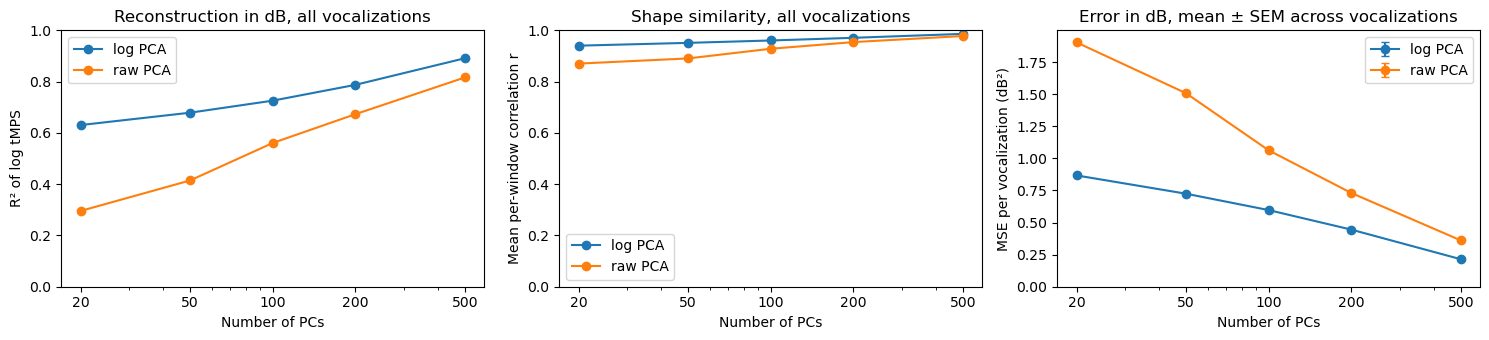

     log R2  log r  log MSE  raw R2  raw r  raw MSE
PCs                                                
20    0.631  0.940    0.867   0.296  0.870    1.904
50    0.679  0.951    0.725   0.414  0.890    1.508
100   0.726  0.960    0.597   0.561  0.928    1.063
200   0.787  0.971    0.445   0.673  0.954    0.730
500   0.891  0.986    0.214   0.816  0.978    0.361


In [12]:
R2_all = {m: 1 - SSE[m].sum(axis=0)/SST.sum() for m in MODELS}
# window-weighted mean of the per-window correlation
r_all = {m: np.nansum(corr[m]*n_win[:, None], axis=0)/n_win[np.isfinite(corr[m][:, 0])].sum() for m in MODELS}

# MSE per vocalization (dB²): squared error averaged over the MPS features, then over the windows (tmps) of the vocalization
n_feat = int(feat_keep.sum())
MSE_voc = {m: SSE[m]/np.where(n_win > 0, n_win, np.nan)[:, None]/n_feat for m in MODELS}   # (n vocalizations, n PCs)
MSE_all = {m: np.nanmean(MSE_voc[m], axis=0) for m in MODELS}                               # mean across vocalizations
MSE_sem = {m: np.nanstd(MSE_voc[m], axis=0)/np.sqrt(np.isfinite(MSE_voc[m]).sum(axis=0)) for m in MODELS}

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3.5))
for m, col in zip(MODELS, ['tab:blue', 'tab:orange']):
    ax1.plot(N_PCS, R2_all[m], 'o-', color=col, label=f'{m} PCA')
    ax2.plot(N_PCS, r_all[m], 'o-', color=col, label=f'{m} PCA')
    ax3.errorbar(N_PCS, MSE_all[m], yerr=MSE_sem[m], fmt='o-', color=col, capsize=3, label=f'{m} PCA')
for ax, lab in zip((ax1, ax2, ax3), ('R² of log tMPS', 'Mean per-window correlation r', 'MSE per vocalization (dB²)')):
    ax.set_xscale('log')
    ax.set_xticks(N_PCS)
    ax.set_xticklabels(N_PCS)
    ax.set_xlabel('Number of PCs')
    ax.set_ylabel(lab)
    ax.legend()
ax1.set_ylim(0, 1)
ax2.set_ylim(0, 1)
ax3.set_ylim(bottom=0)
ax1.set_title('Reconstruction in dB, all vocalizations')
ax2.set_title('Shape similarity, all vocalizations')
ax3.set_title('Error in dB, mean ± SEM across vocalizations')
plt.tight_layout()
plt.show()

print(pd.DataFrame({f'{m} {stat}': vals for m in MODELS for stat, vals in (('R2', R2_all[m]), ('r', r_all[m]), ('MSE', MSE_all[m]))},
                   index=pd.Index(N_PCS, name='PCs')).round(3).to_string())

## Reconstruction quality per call type

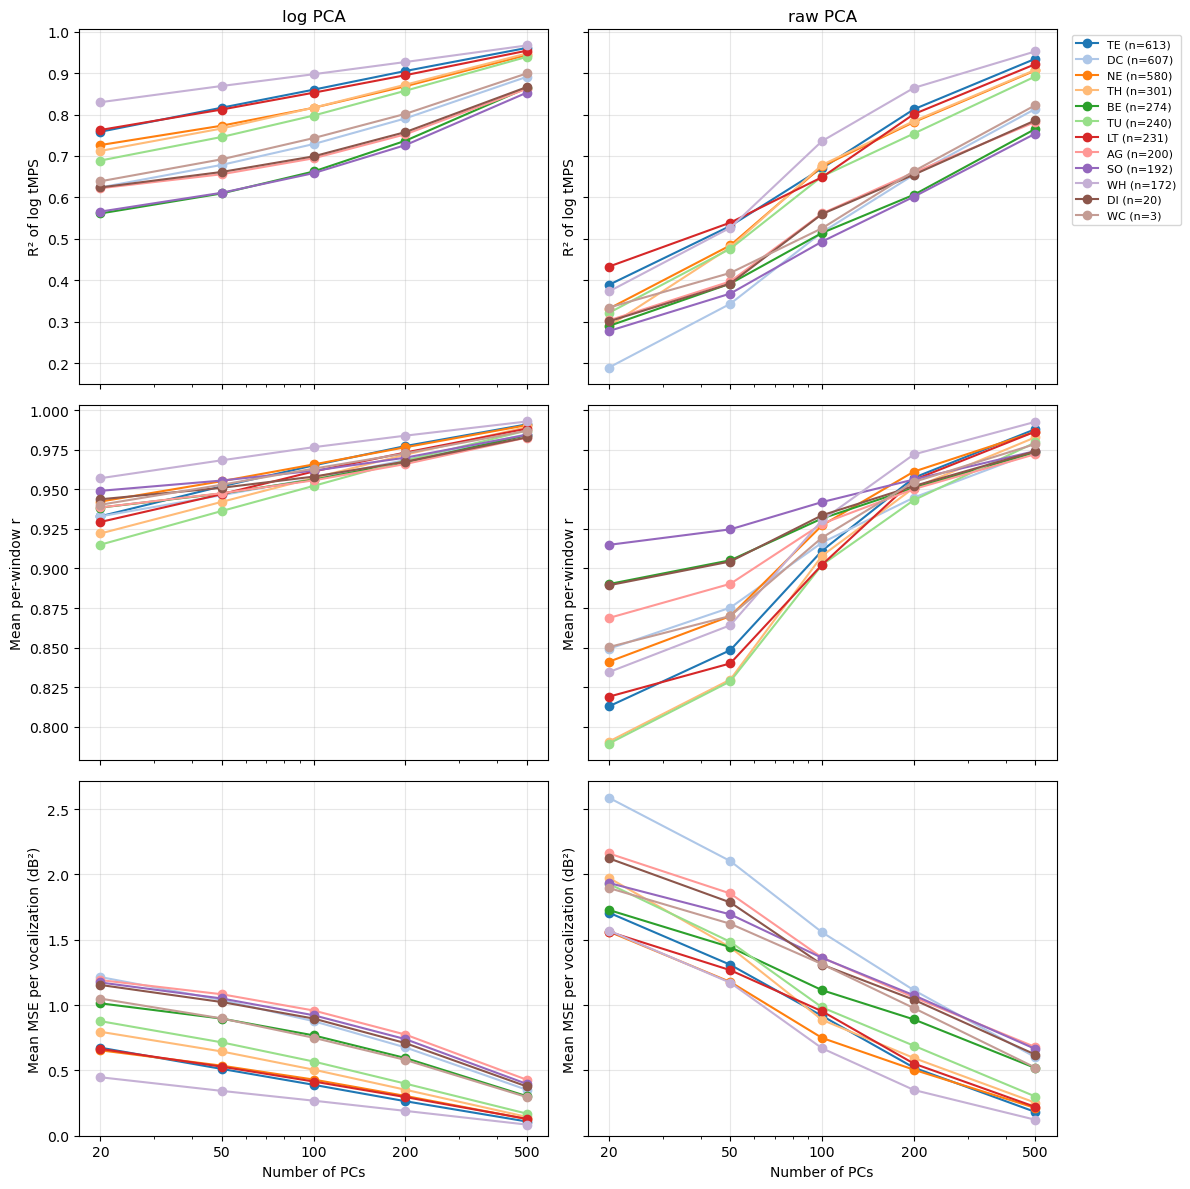

R² per call type
      log                                raw                                n
       20     50    100    200    500     20     50    100    200    500     
TE  0.758  0.817  0.860  0.905  0.961  0.389  0.531  0.671  0.813  0.935  613
DC  0.624  0.679  0.729  0.791  0.891  0.189  0.343  0.516  0.655  0.814  607
NE  0.726  0.773  0.816  0.868  0.944  0.332  0.484  0.675  0.782  0.906  580
TH  0.712  0.766  0.817  0.872  0.947  0.289  0.479  0.678  0.784  0.908  301
BE  0.561  0.610  0.663  0.737  0.864  0.290  0.392  0.514  0.606  0.765  274
TU  0.689  0.746  0.798  0.857  0.939  0.321  0.476  0.651  0.754  0.892  240
LT  0.763  0.812  0.853  0.895  0.954  0.433  0.539  0.649  0.801  0.922  231
AG  0.622  0.656  0.694  0.752  0.862  0.303  0.397  0.561  0.660  0.782  200
SO  0.566  0.611  0.659  0.726  0.853  0.278  0.368  0.493  0.602  0.754  192
WH  0.830  0.869  0.897  0.927  0.967  0.373  0.527  0.736  0.864  0.952  172
DI  0.624  0.661  0.699  0.758  0.866  0.301  0

In [13]:
def pooled_R2(mask, m):
    return 1 - SSE[m][mask].sum(axis=0)/SST[mask].sum()

def pooled_r(mask, m):
    c, w = corr[m][mask], n_win[mask]
    ok = np.isfinite(c[:, 0])
    return (c[ok]*w[ok, None]).sum(axis=0)/w[ok].sum()

R2_ct = {m: pd.DataFrame([pooled_R2(calltype_f == ct, m) for ct in CALLTYPES], index=CALLTYPES, columns=N_PCS) for m in MODELS}
r_ct = {m: pd.DataFrame([pooled_r(calltype_f == ct, m) for ct in CALLTYPES], index=CALLTYPES, columns=N_PCS) for m in MODELS}
MSE_ct = {m: pd.DataFrame([np.nanmean(MSE_voc[m][calltype_f == ct], axis=0) for ct in CALLTYPES], index=CALLTYPES, columns=N_PCS) for m in MODELS}

cmap_ct = plt.get_cmap('tab20')
fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True, sharey='row')
for col, m in enumerate(MODELS):
    for c, ct in enumerate(CALLTYPES):
        axes[0, col].plot(N_PCS, R2_ct[m].loc[ct], 'o-', color=cmap_ct(c), label=f'{ct} (n={ct_counts[ct]})')
        axes[1, col].plot(N_PCS, r_ct[m].loc[ct], 'o-', color=cmap_ct(c))
        axes[2, col].plot(N_PCS, MSE_ct[m].loc[ct], 'o-', color=cmap_ct(c))
    axes[0, col].set_title(f'{m} PCA')
    axes[0, col].set_ylabel('R² of log tMPS')
    axes[1, col].set_ylabel('Mean per-window r')
    axes[2, col].set_ylabel('Mean MSE per vocalization (dB²)')
    axes[2, col].set_xlabel('Number of PCs')
for ax in axes.flatten():
    ax.set_xscale('log')
    ax.set_xticks(N_PCS)
    ax.set_xticklabels(N_PCS)
    ax.grid(alpha=0.3)
axes[2, 0].set_ylim(bottom=0)
axes[0, 1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print('R² per call type')
print(pd.concat({m: R2_ct[m] for m in MODELS}, axis=1).assign(n=ct_counts).round(3).to_string())
print('\nMean per-window r per call type')
print(pd.concat({m: r_ct[m] for m in MODELS}, axis=1).assign(n=ct_counts).round(3).to_string())
print('\nMean MSE per vocalization per call type (dB²)')
print(pd.concat({m: MSE_ct[m] for m in MODELS}, axis=1).assign(n=ct_counts).round(2).to_string())

### Spread across vocalizations
R² and MSE of each vocalization for a chosen number of PCs. SST is computed relative to the dataset-mean MPS, so vocalizations whose MPS is far from the average one have a larger SST and can reach a higher R² for the same error in dB. MSE does not depend on that reference: it is the error itself, in dB².

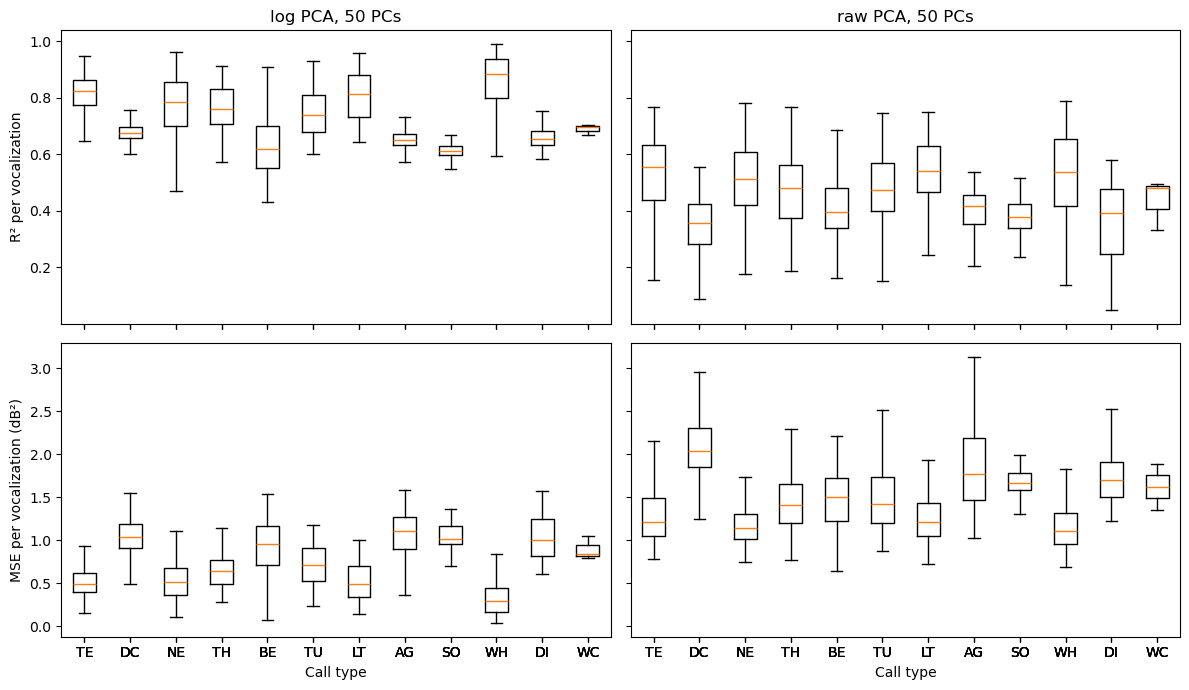

In [14]:
K_SHOW = 50                          # number of PCs shown
j = N_PCS.index(K_SHOW)
valid_v = n_win > 0
R2_voc = {m: np.where(valid_v, 1 - SSE[m][:, j]/np.where(SST > 0, SST, np.nan), np.nan) for m in MODELS}

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey='row')
for col, m in enumerate(MODELS):
    for row, (vals, lab) in enumerate(((R2_voc[m], 'R² per vocalization'), (MSE_voc[m][:, j], 'MSE per vocalization (dB²)'))):
        data = [vals[(calltype_f == ct) & valid_v] for ct in CALLTYPES]
        axes[row, col].boxplot(data, labels=CALLTYPES, showfliers=False)
        axes[row, 0].set_ylabel(lab)
    axes[0, col].set_title(f'{m} PCA, {K_SHOW} PCs')
    axes[1, col].set_xlabel('Call type')
plt.tight_layout()
plt.show()

## Examples: one vocalization per call type
For each call type, the vocalization with the median R² (log PCA, `K_EX` PCs) is shown. Top: spectrogram with the MPS window displayed below (dashed lines) and the per-window correlation r over time for each reconstruction. Middle: original log MPS and log-PCA reconstructions. Bottom: original log MPS and raw-PCA reconstructions. The title of each reconstruction gives r and MSE (dB², averaged over the MPS features) for the window shown, not for the whole vocalization. All MPSs are in dB above the floor, on the same color scale.

In [17]:
K_EX = 200                      # number of PCs used to pick the median example
KS_EX = (20, 100, 200, 500)    # numbers of PCs shown in the example reconstructions
WT_LIM = 500                   # temporal modulation range shown (Hz)
WF_LIM = 8                     # spectral modulation range shown (cycles/kHz)
DBNOISE = 50                   # dynamic range of the spectrogram display (dB)

def plot_reconstruction_example(i, ks=KS_EX, win=None, winMPS=100):
    # spectrogram, per-window correlation over time, and original vs reconstructed MPS of vocalization i
    # win: index of the window shown (in non-silent windows); default is the window with the most energy
    with h5py.File(h5files[i], 'r') as f:
        tmps = np.atleast_2d(f['tmps'][()])
        spectro, to, fo, tmps_t = f['spectro'][()], f['to'][()], f['fo'][()], f['tmps_t'][()]
        label = ' '.join(f[key][()].decode() for key in ('emitter', 'type', 'rendition'))
    valid = np.isfinite(tmps).all(axis=1)
    t_end = tmps_t[1:][valid]                        # end of each non-silent MPS window (ms)
    tmps = tmps[valid][:, feat_keep]
    Xdb = to_db(tmps)
    Z = {m: project(tmps, m) for m in MODELS}
    R = {(m, k): reconstruct_db(Z[m], m, k) for m in MODELS for k in ks}
    if win is None:
        win = np.argmax(Xdb.sum(axis=1))

    fig = plt.figure(figsize=(4*(len(ks)+1), 10))
    gs = fig.add_gridspec(3, len(ks)+1)

    # spectrogram with the displayed MPS window
    ax_s = fig.add_subplot(gs[0, :(len(ks)+1)//2])
    spec = np.where(np.isfinite(spectro), spectro, np.nan)
    vmax = np.nanmax(spec)
    spec_colormap()   # defined in sound.py
    ax_s.imshow(spec, aspect='auto', origin='lower', cmap=plt.get_cmap('SpectroColorMap'), vmin=vmax-DBNOISE, vmax=vmax,
                extent=(to[0]*1000, to[-1]*1000, fo[0]/1000, fo[-1]/1000))
    for t in (t_end[win]-winMPS, t_end[win]):
        ax_s.axvline(t, color='k', ls='--', lw=1)
    ax_s.set_xlim(t_end[0]-winMPS, t_end[-1])
    ax_s.set_xlabel('Time (ms)')
    ax_s.set_ylabel('Frequency (kHz)')
    ax_s.set_title(f'voc {i} (n={file_n[i]}): {label}')

    # per-window correlation over time
    ax_r = fig.add_subplot(gs[0, (len(ks)+1)//2:])
    for k, col in zip(ks, plt.get_cmap('viridis')(np.linspace(0, 0.85, len(ks)))):
        for m, ls in zip(MODELS, ('-', '--')):
            ax_r.plot(t_end - winMPS/2, row_corr(Xdb, R[(m, k)]), ls, color=col, label=f'{m} {k} PCs')
    ax_r.axvline(t_end[win] - winMPS/2, color='k', lw=0.8)
    ax_r.set_ylim(0, 1)
    ax_r.set_xlabel('Time (ms, center of MPS window)')
    ax_r.set_ylabel('r original vs reconstruction')
    ax_r.legend(fontsize=7, ncol=2)

    # MPSs, with the correlation and the MSE (dB², averaged over the MPS features) of the window shown
    ex = (tmps_wt.min(), tmps_wt.max(), tmps_wf.min()*1e3, tmps_wf.max()*1e3)
    vmax_mps = Xdb[win].max()
    for row, m in enumerate(MODELS, start=1):
        panels = [('Original', Xdb[win])]
        for k in ks:
            r_win = row_corr(Xdb[win:win+1], R[(m, k)][win:win+1])[0]
            mse_win = ((Xdb[win] - R[(m, k)][win])**2).mean()
            panels.append((f'{m} PCA, {k} PCs\nr={r_win:.2f}, MSE={mse_win:.1f} dB²', R[(m, k)][win]))
        for c, (title, v) in enumerate(panels):
            ax = fig.add_subplot(gs[row, c])
            im = ax.imshow(to_mps(v), aspect='auto', origin='lower', cmap='jet', vmin=0, vmax=vmax_mps,
                           extent=ex, interpolation='nearest')
            ax.set_xlim(-WT_LIM, WT_LIM)
            ax.set_ylim(0, WF_LIM)
            ax.set_title(title, fontsize=9)
            if c == 0:
                ax.set_ylabel('Spectral Frequency (Cycles/KHz)')
            if row == len(MODELS):
                ax.set_xlabel('Temporal Frequency (Hz)')
        fig.colorbar(im, ax=ax, label='dB above floor')
    plt.tight_layout()
    plt.show()

# median example per call type
jE = N_PCS.index(K_EX)
R2_voc_ex = np.where(n_win > 0, 1 - SSE['log'][:, jE]/np.where(SST > 0, SST, np.nan), np.nan)
example_idx = {}
for ct in CALLTYPES:
    idx = np.where((calltype_f == ct) & np.isfinite(R2_voc_ex))[0]
    example_idx[ct] = idx[np.argsort(R2_voc_ex[idx])[len(idx)//2]]
print({ct: int(file_n[i]) for ct, i in example_idx.items()})

{'TE': 515, 'DC': 1754, 'NE': 312, 'TH': 303, 'BE': 3116, 'TU': 1453, 'LT': 3238, 'AG': 2831, 'SO': 2127, 'WH': 616, 'DI': 411, 'WC': 2312}


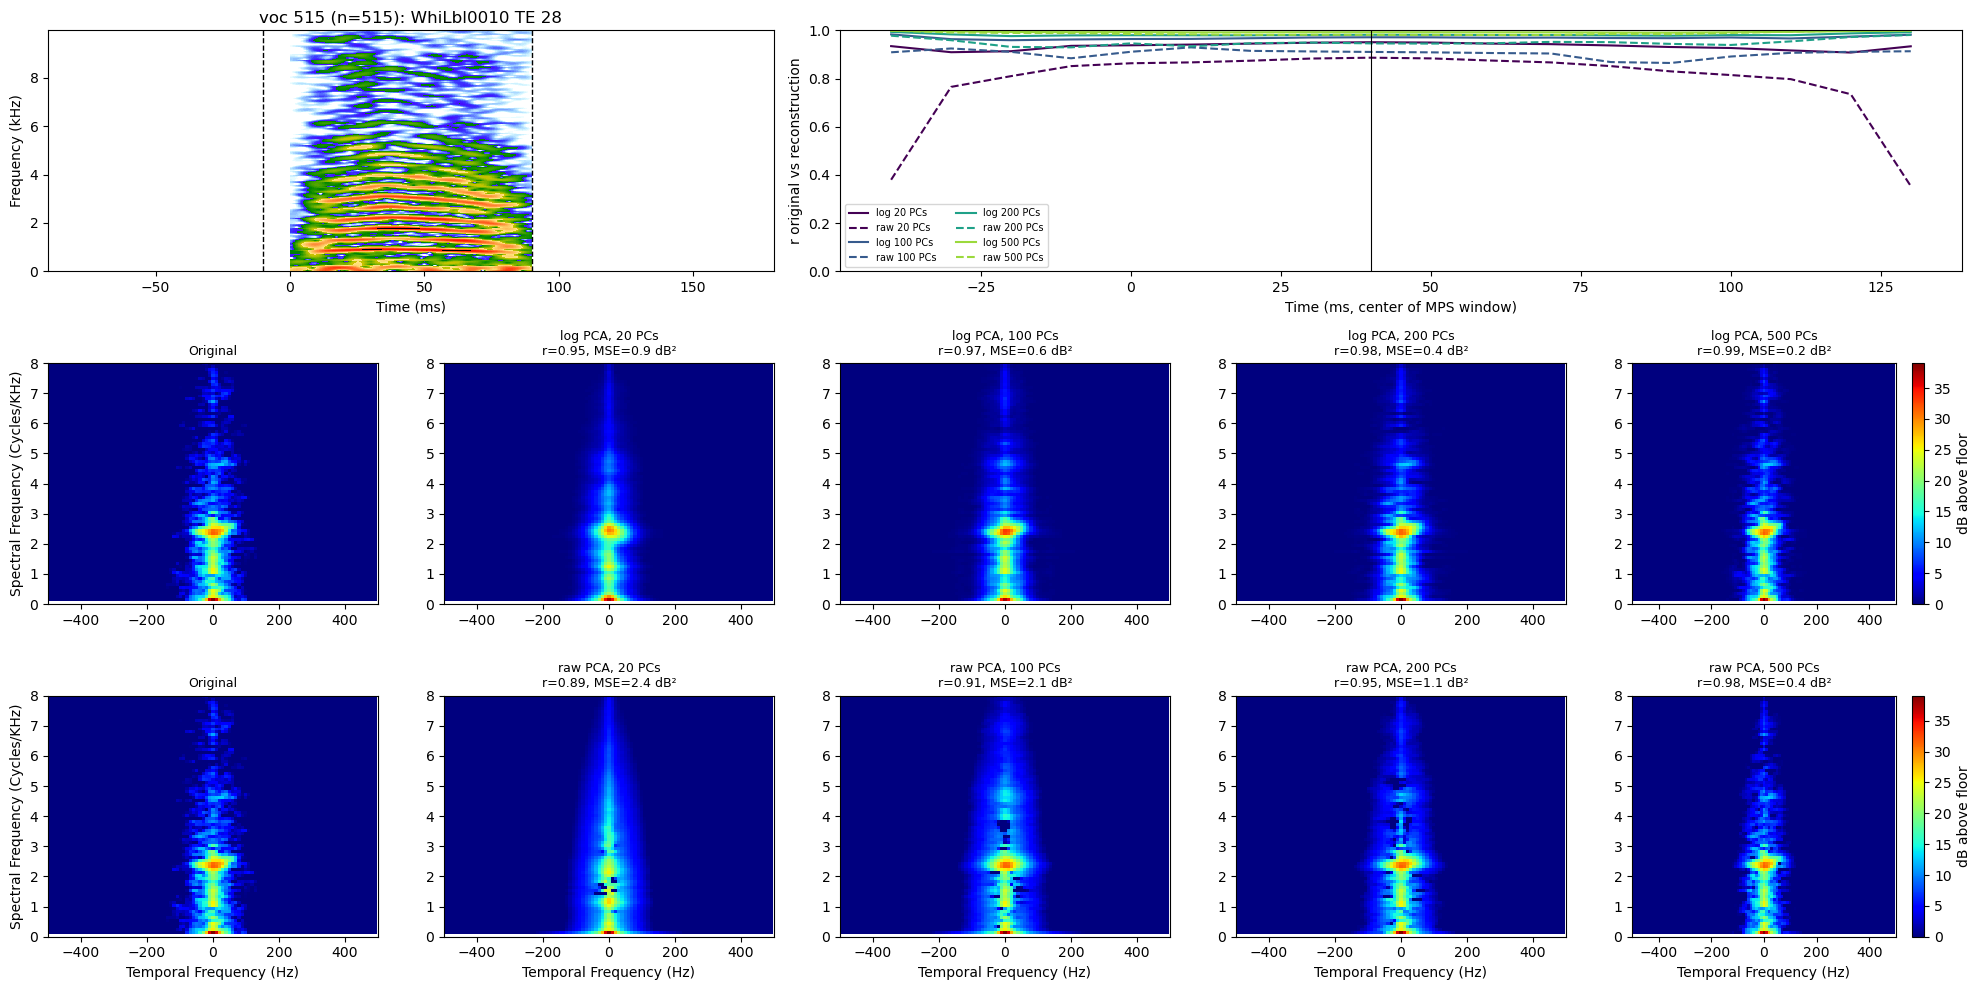

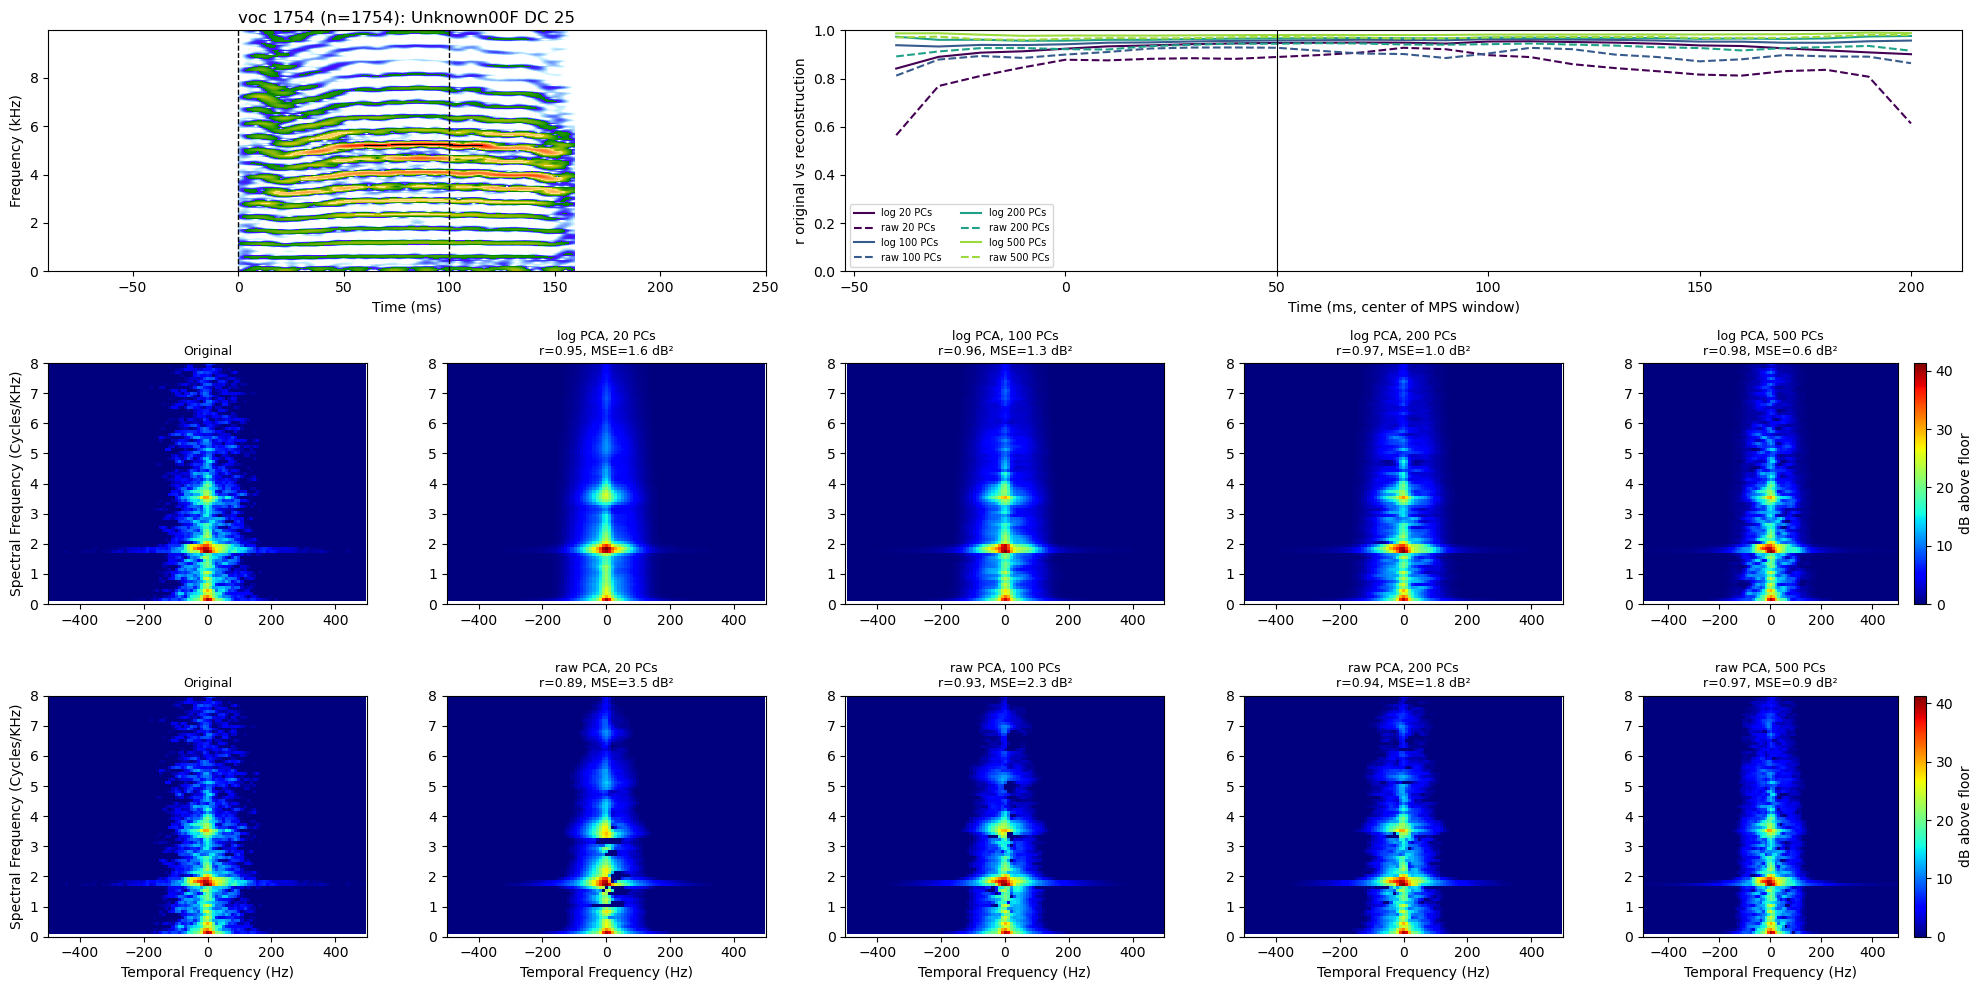

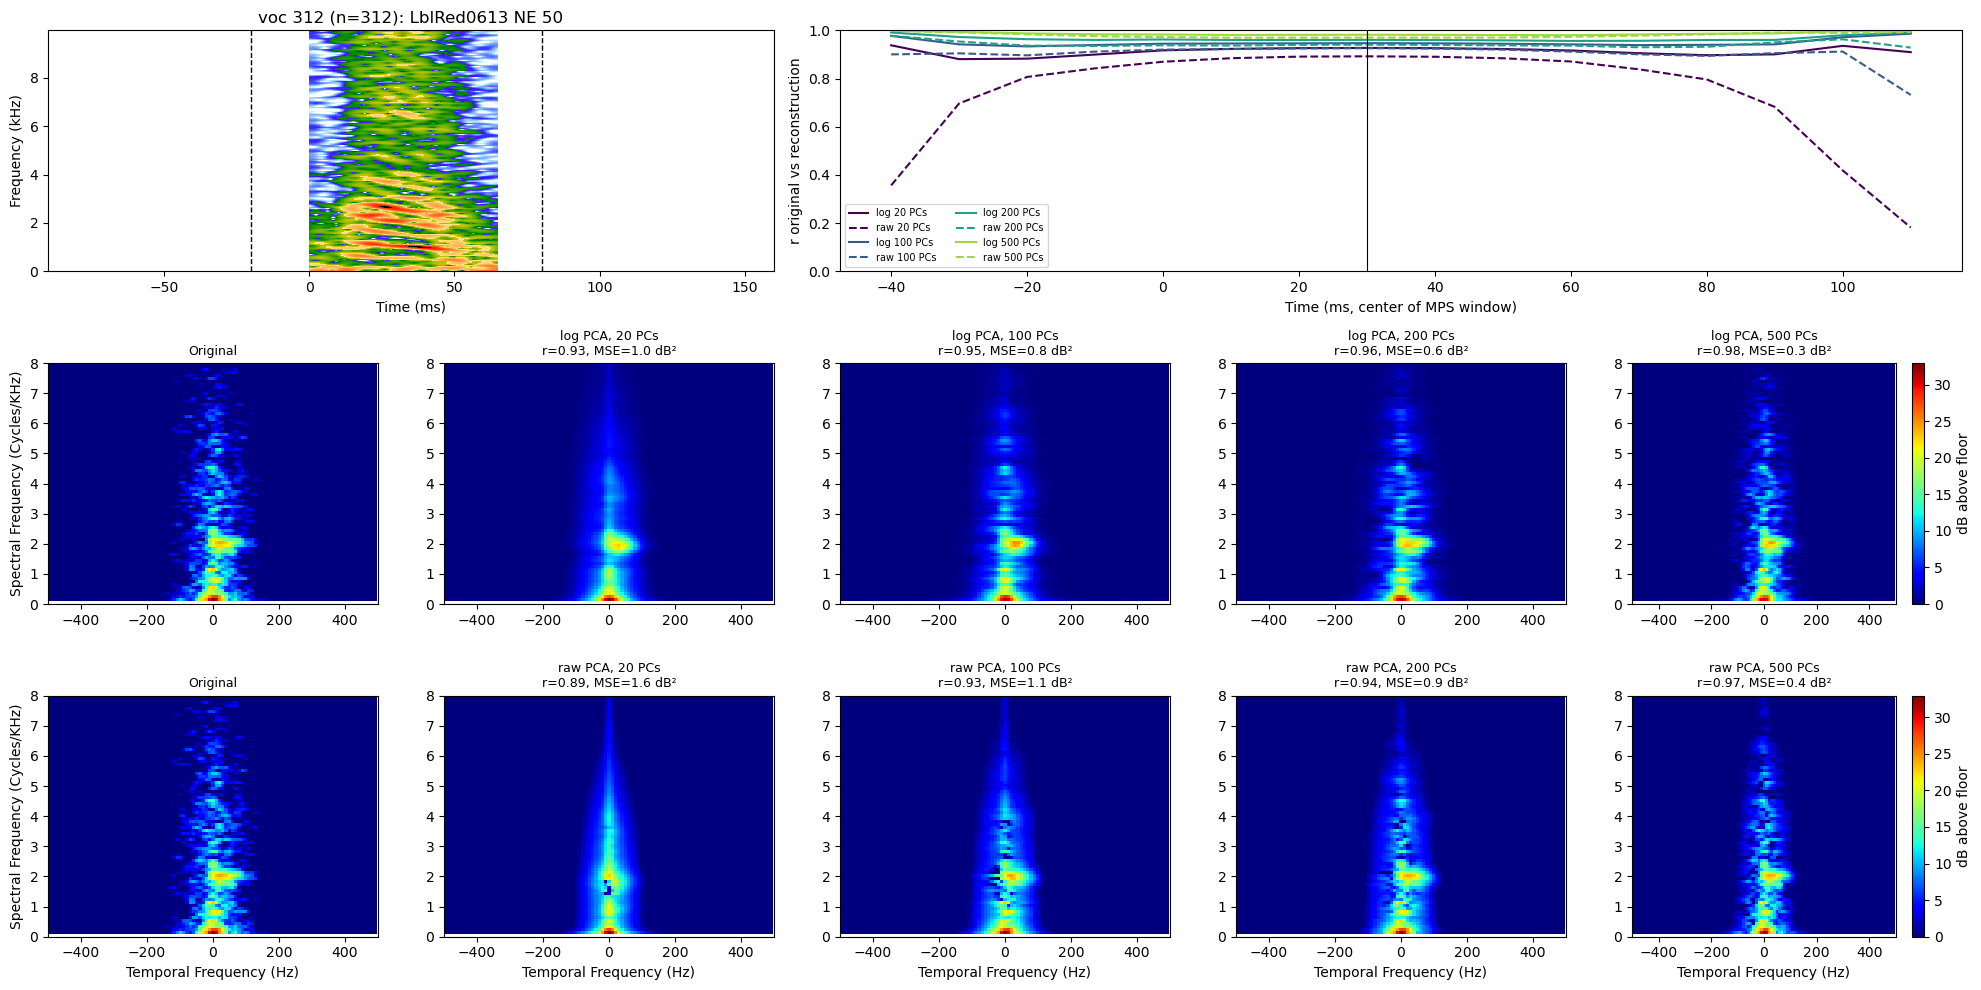

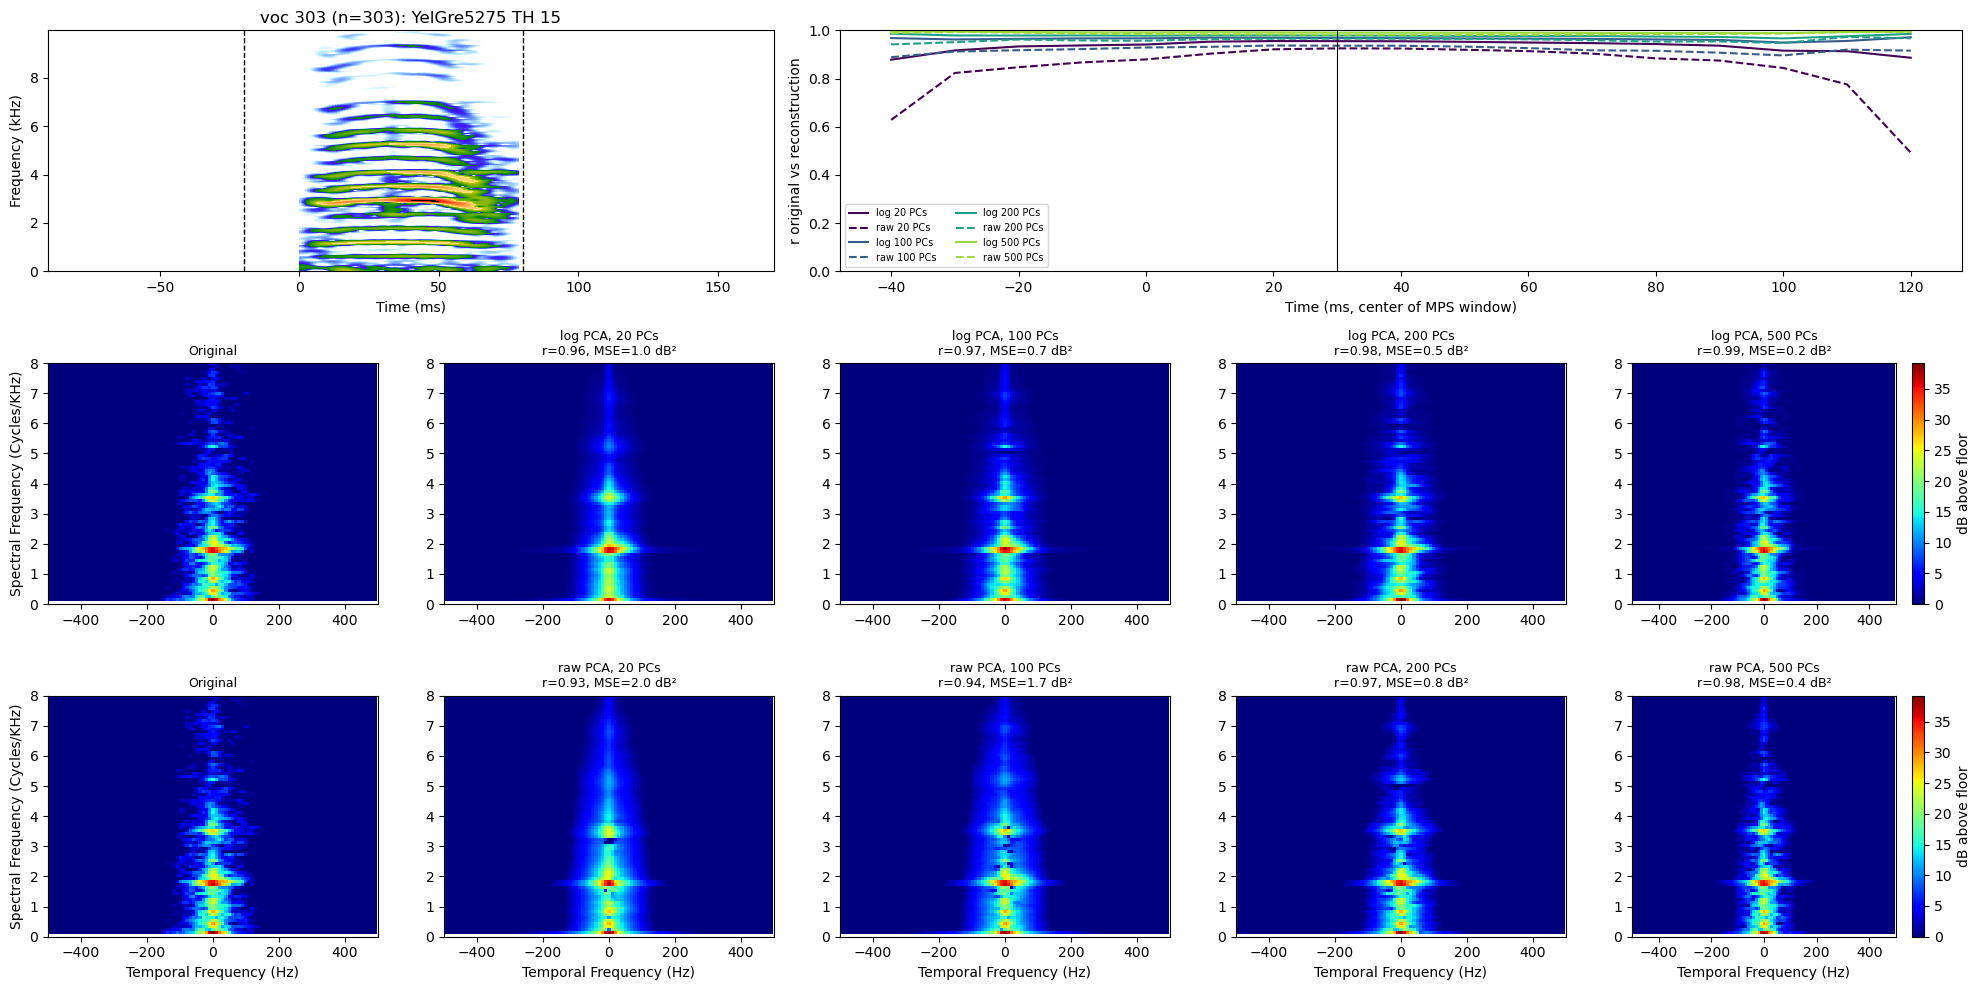

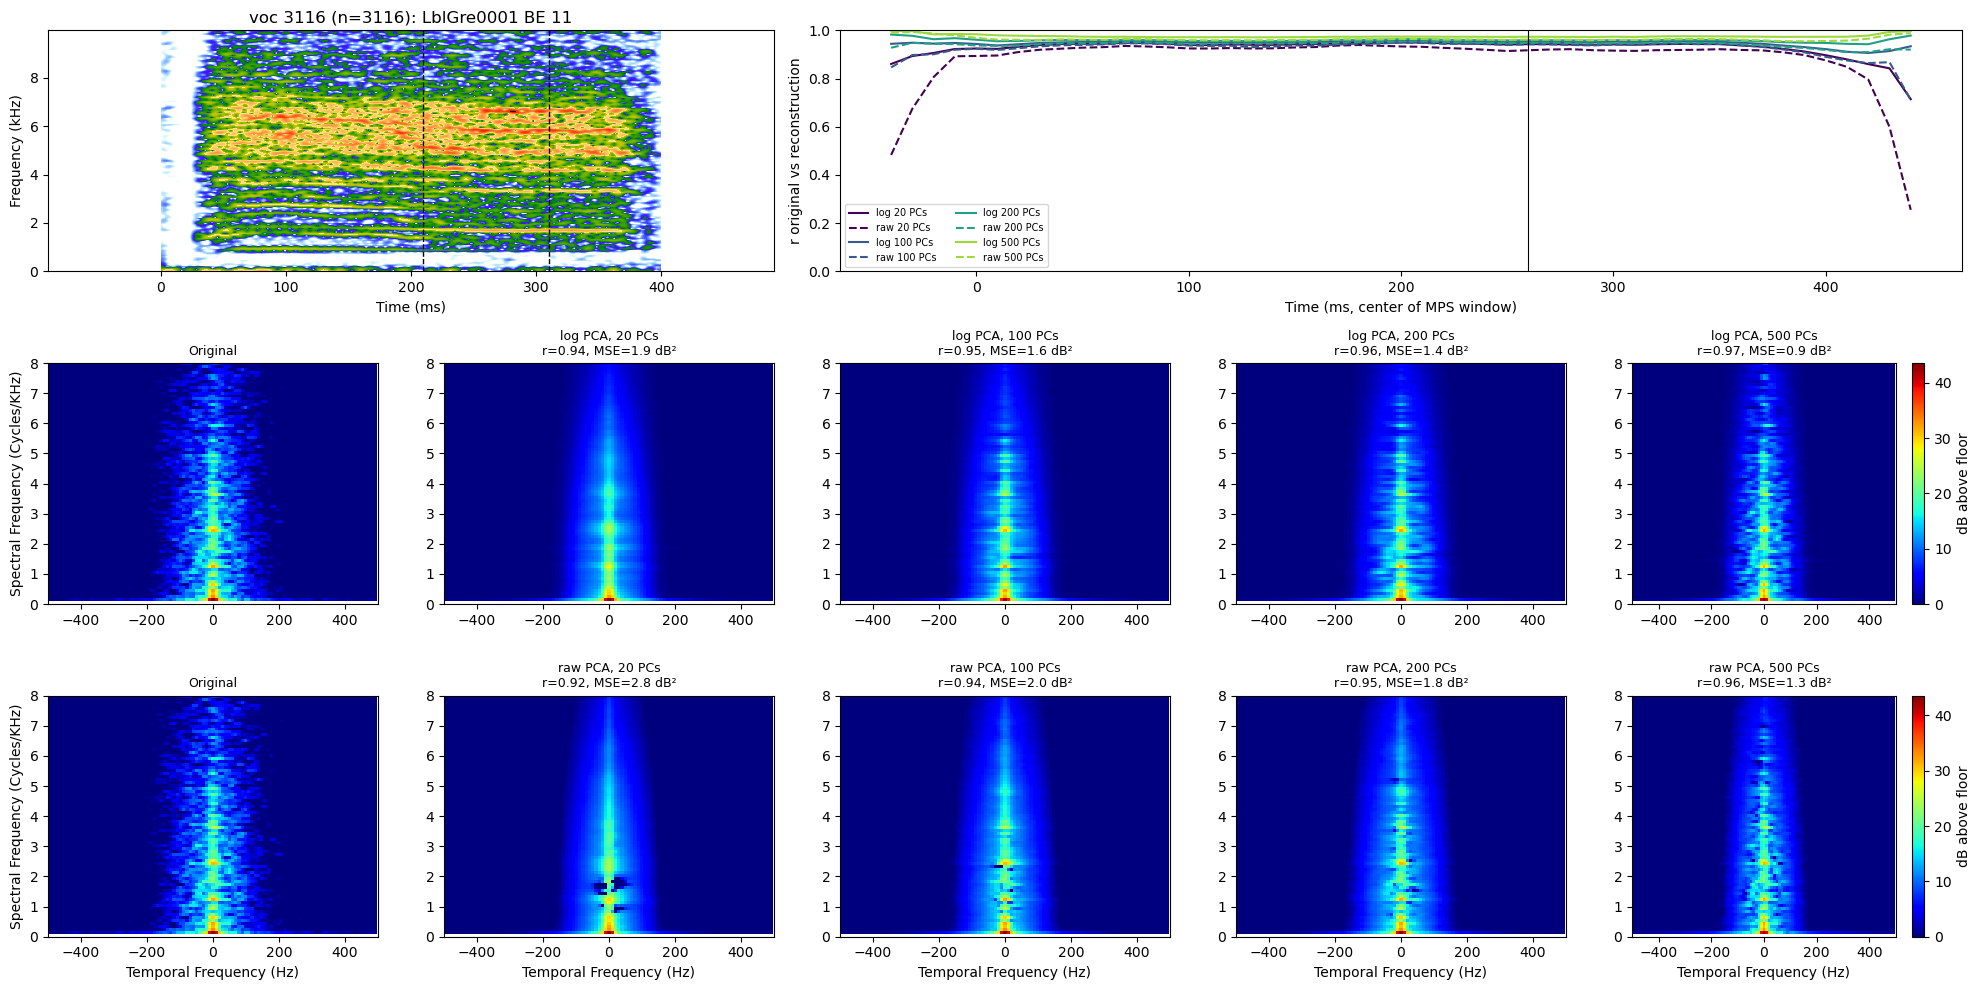

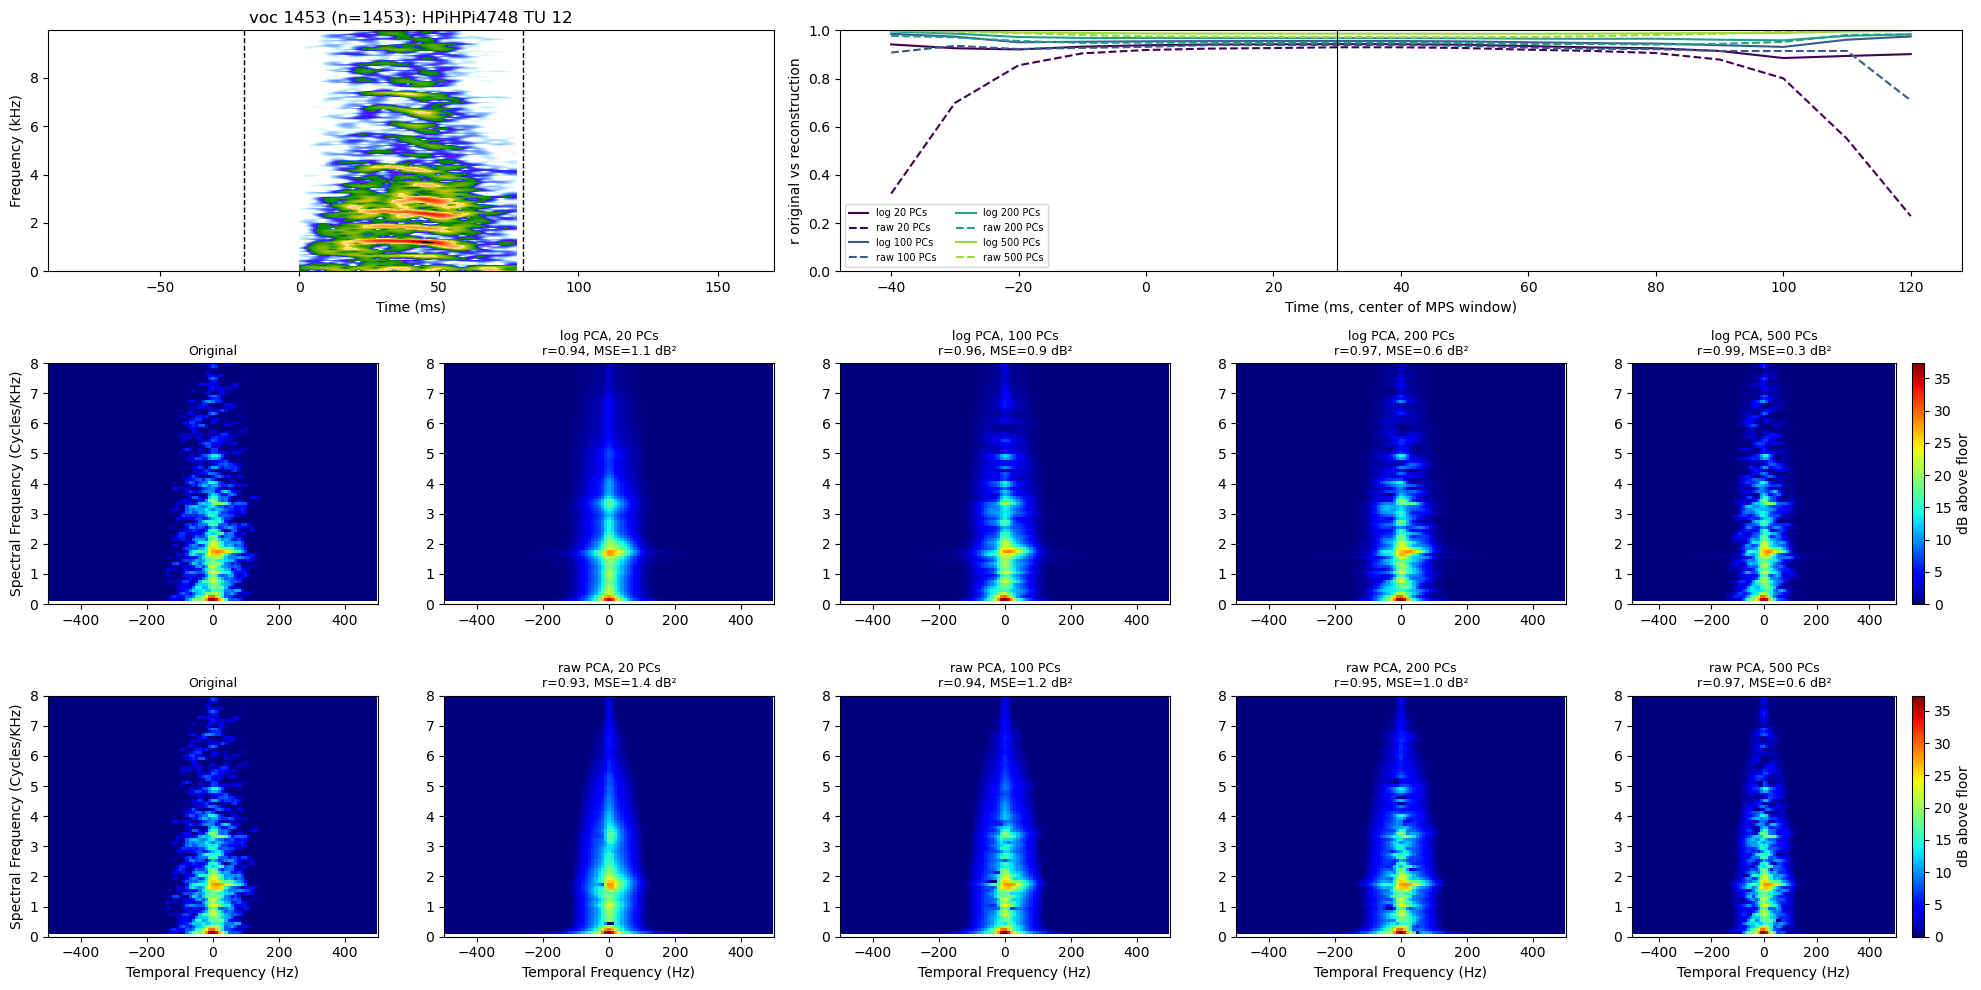

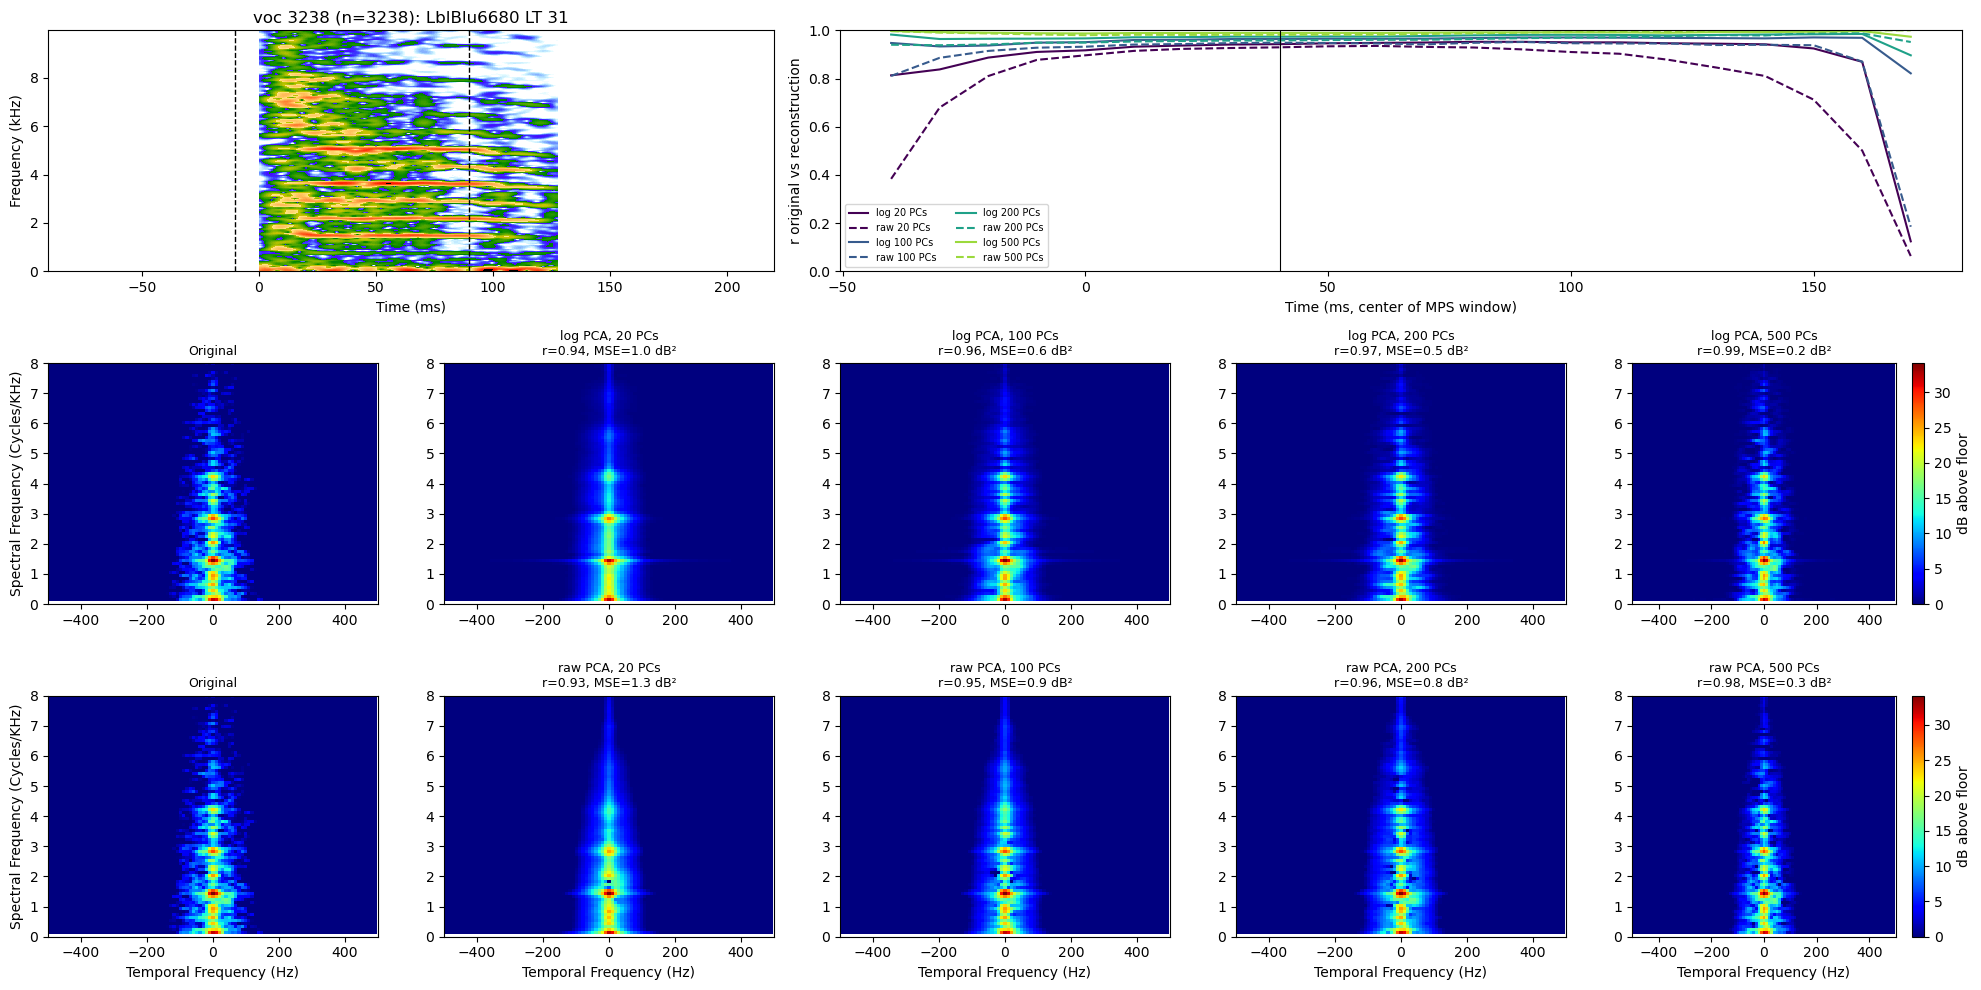

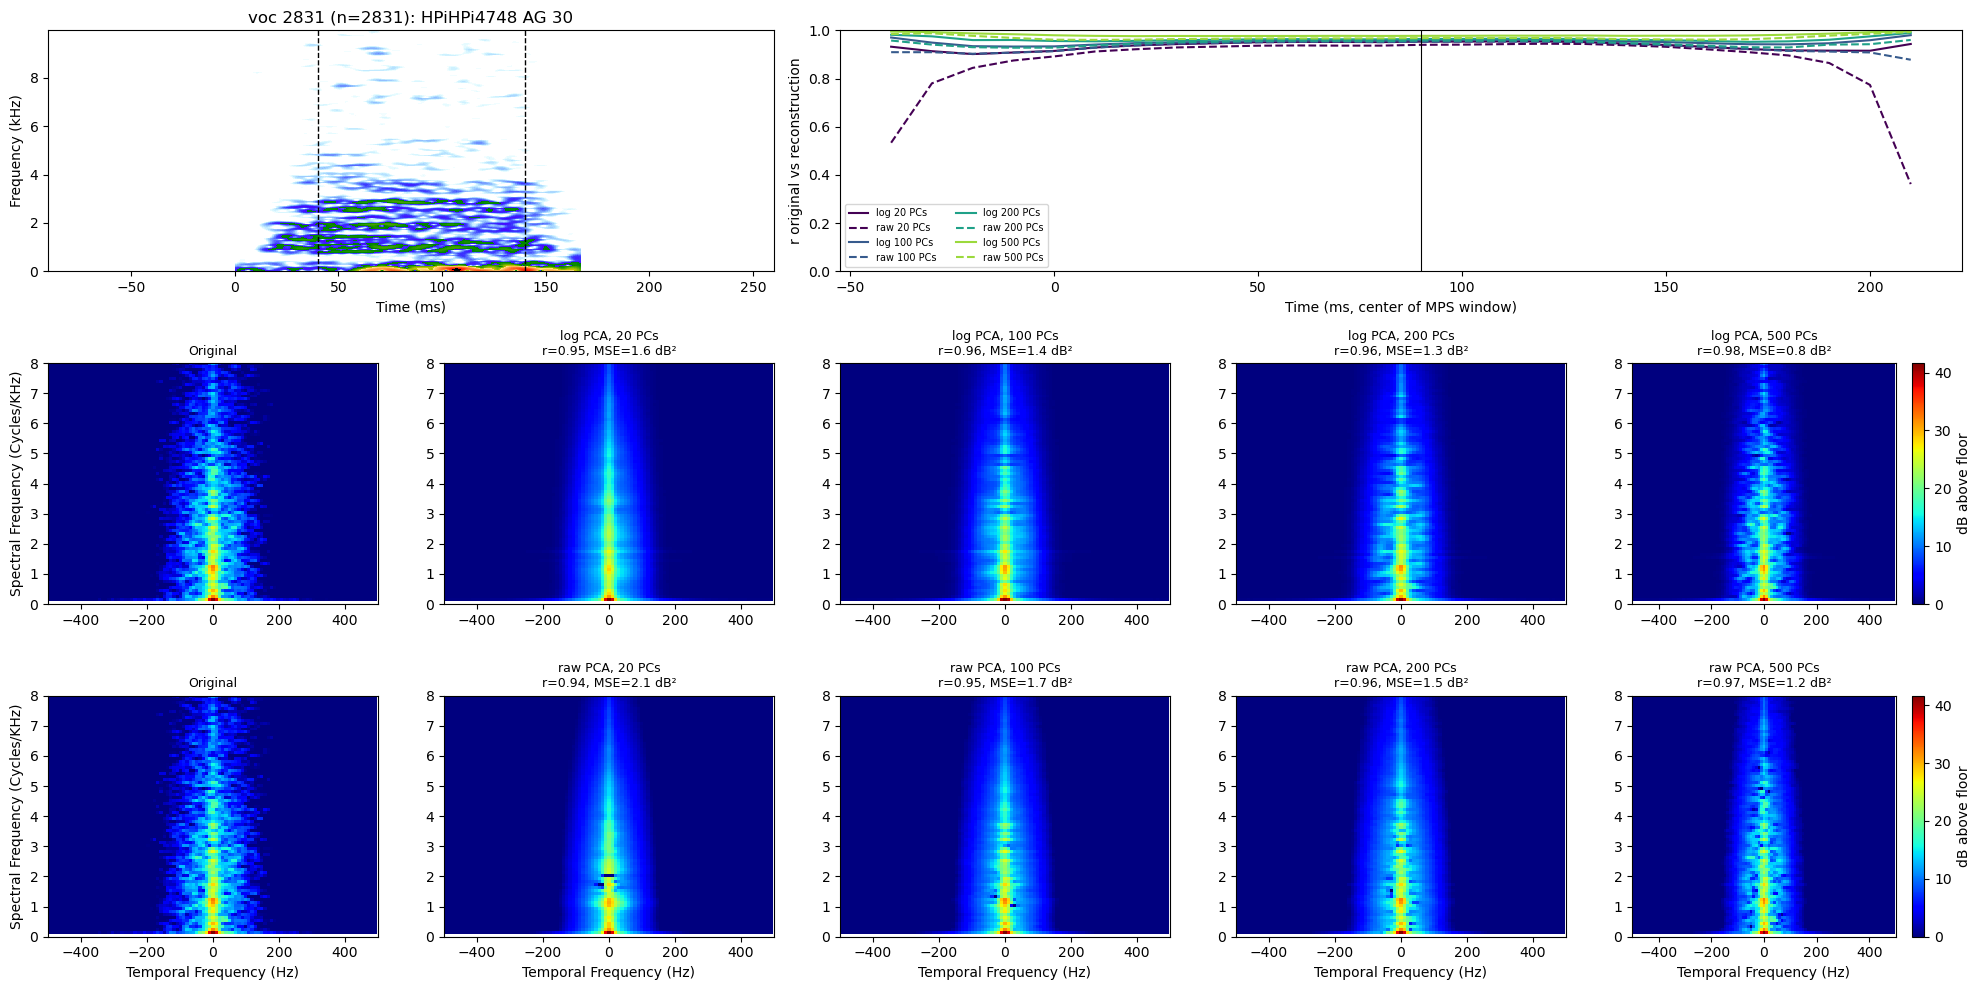

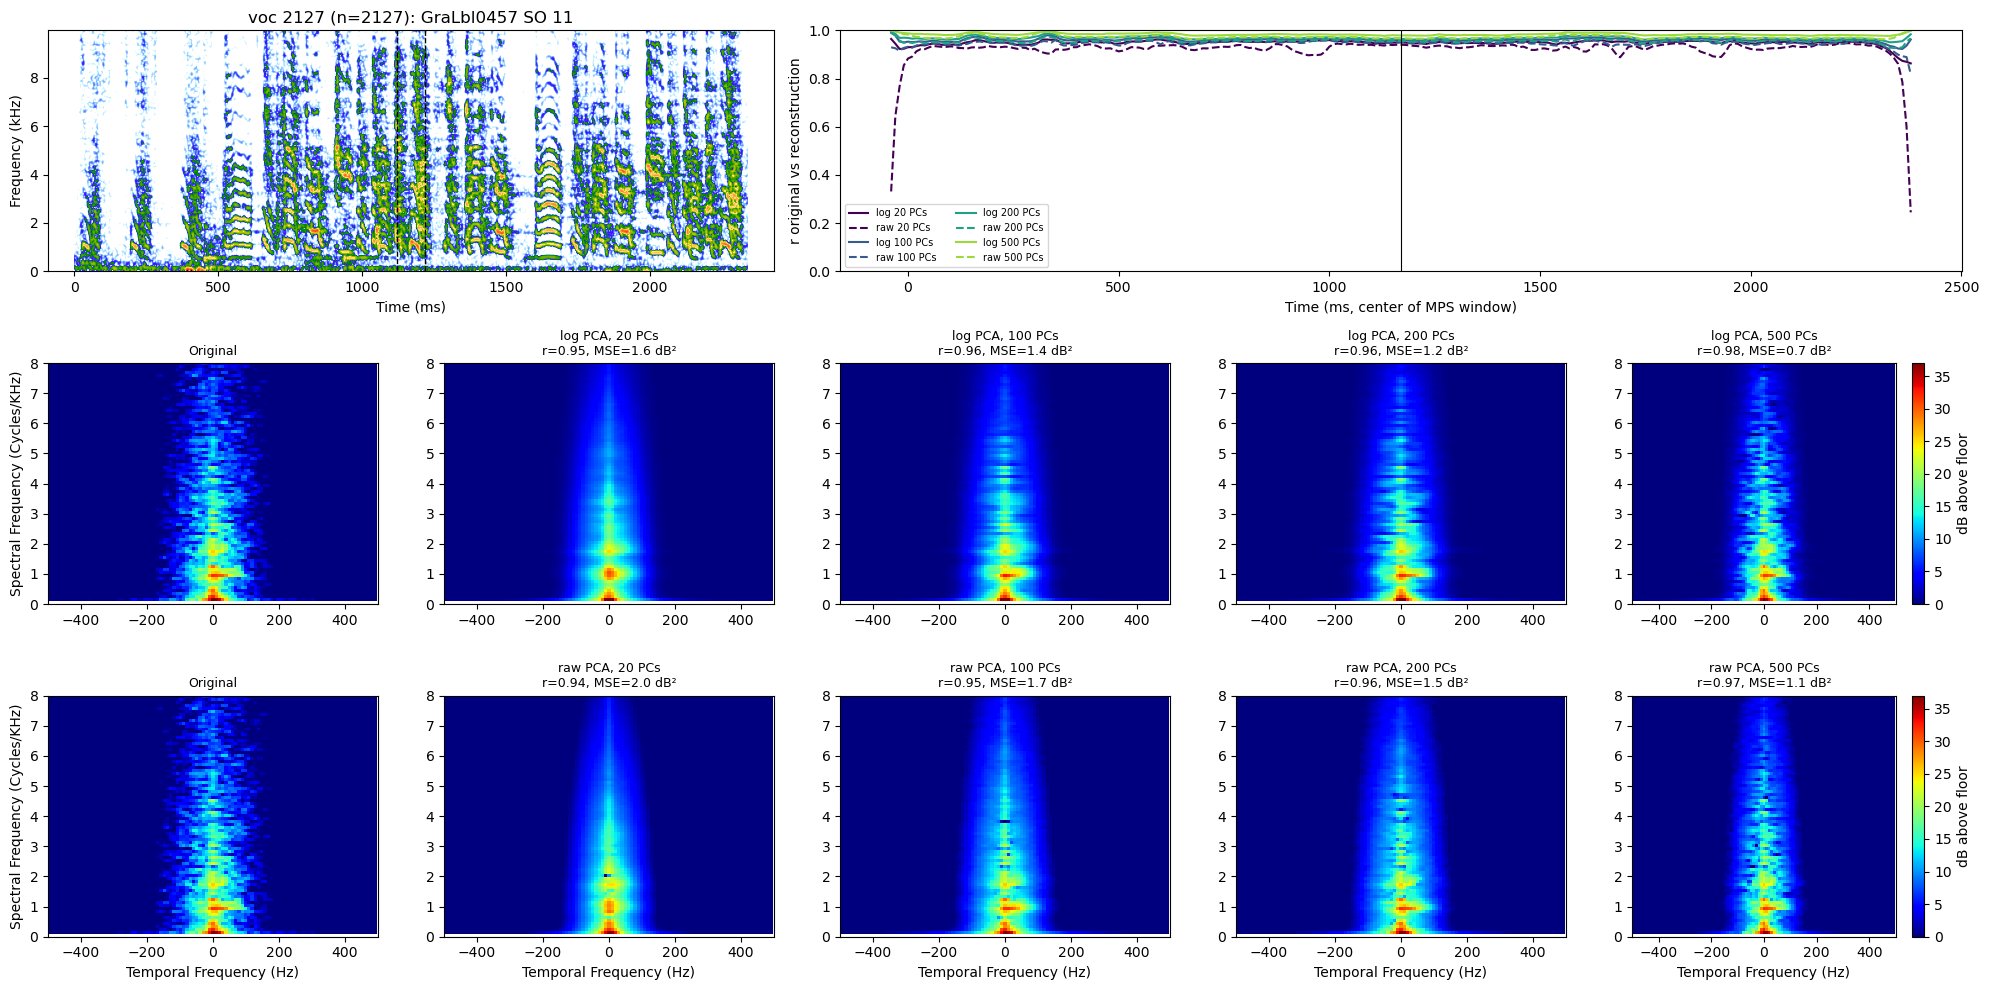

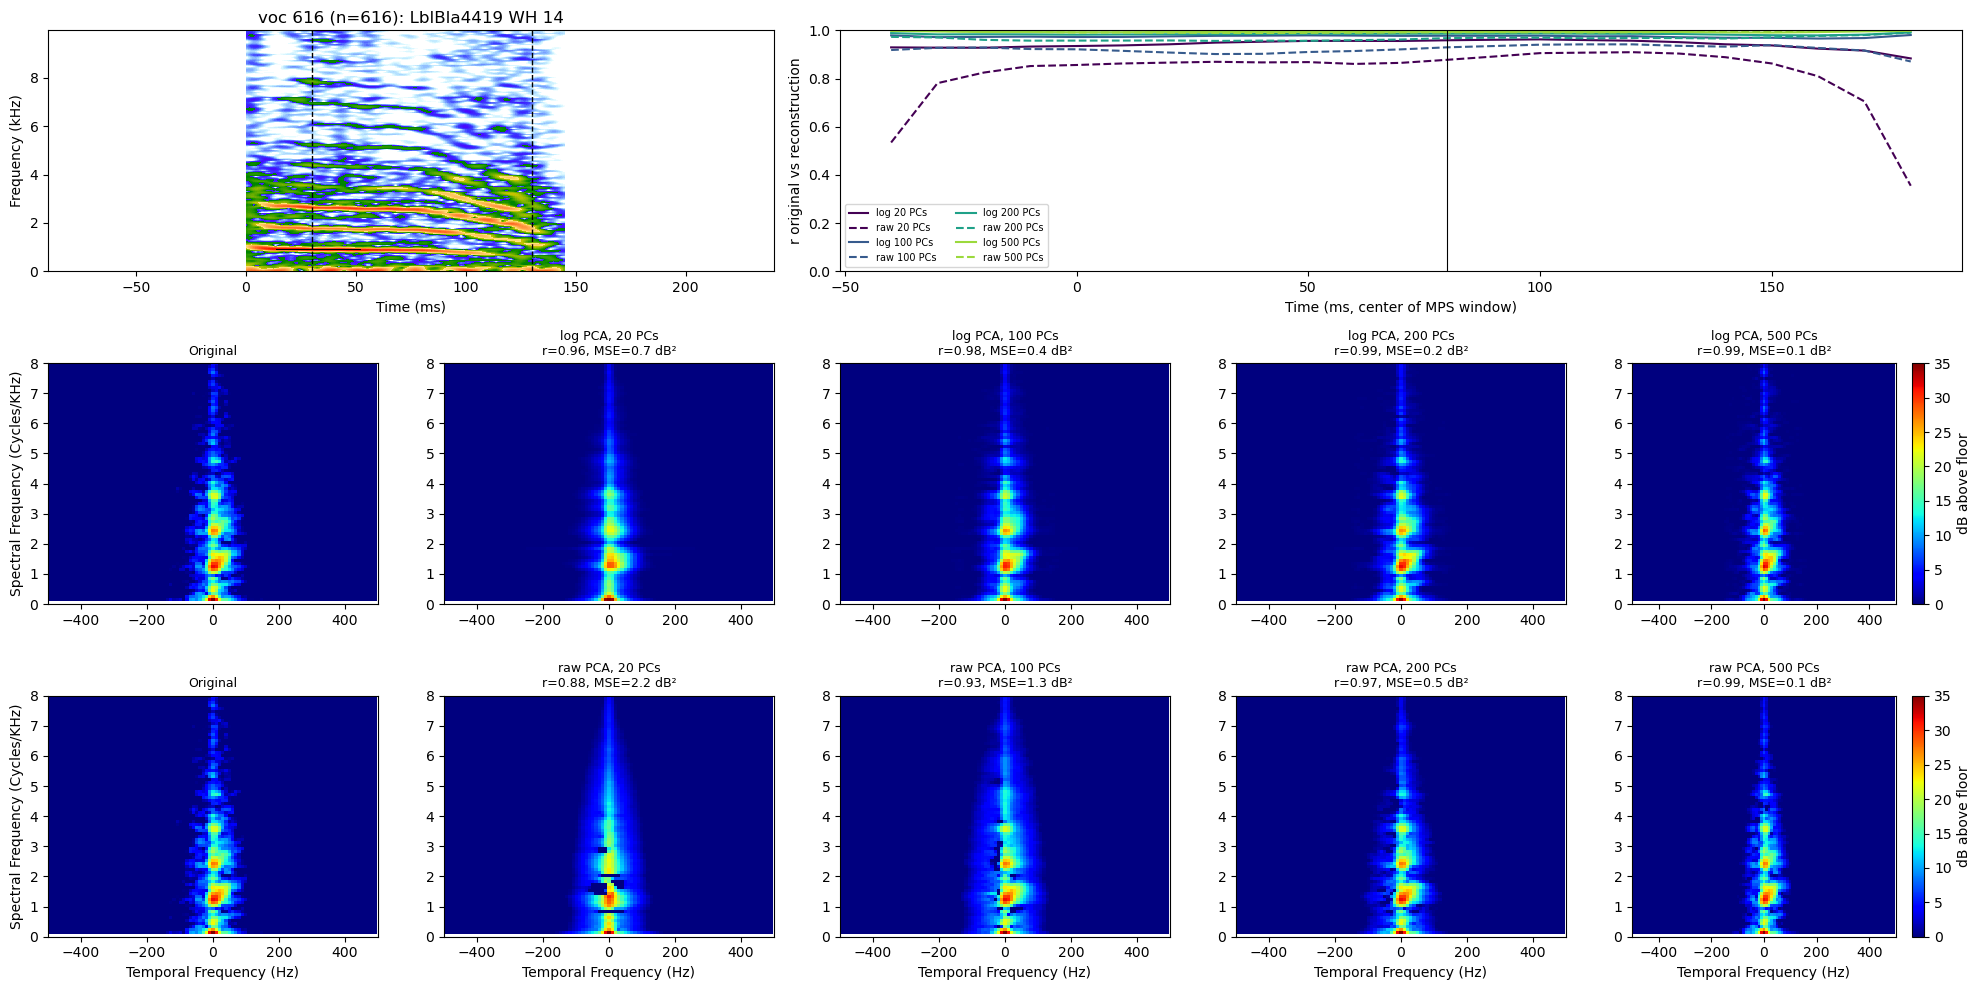

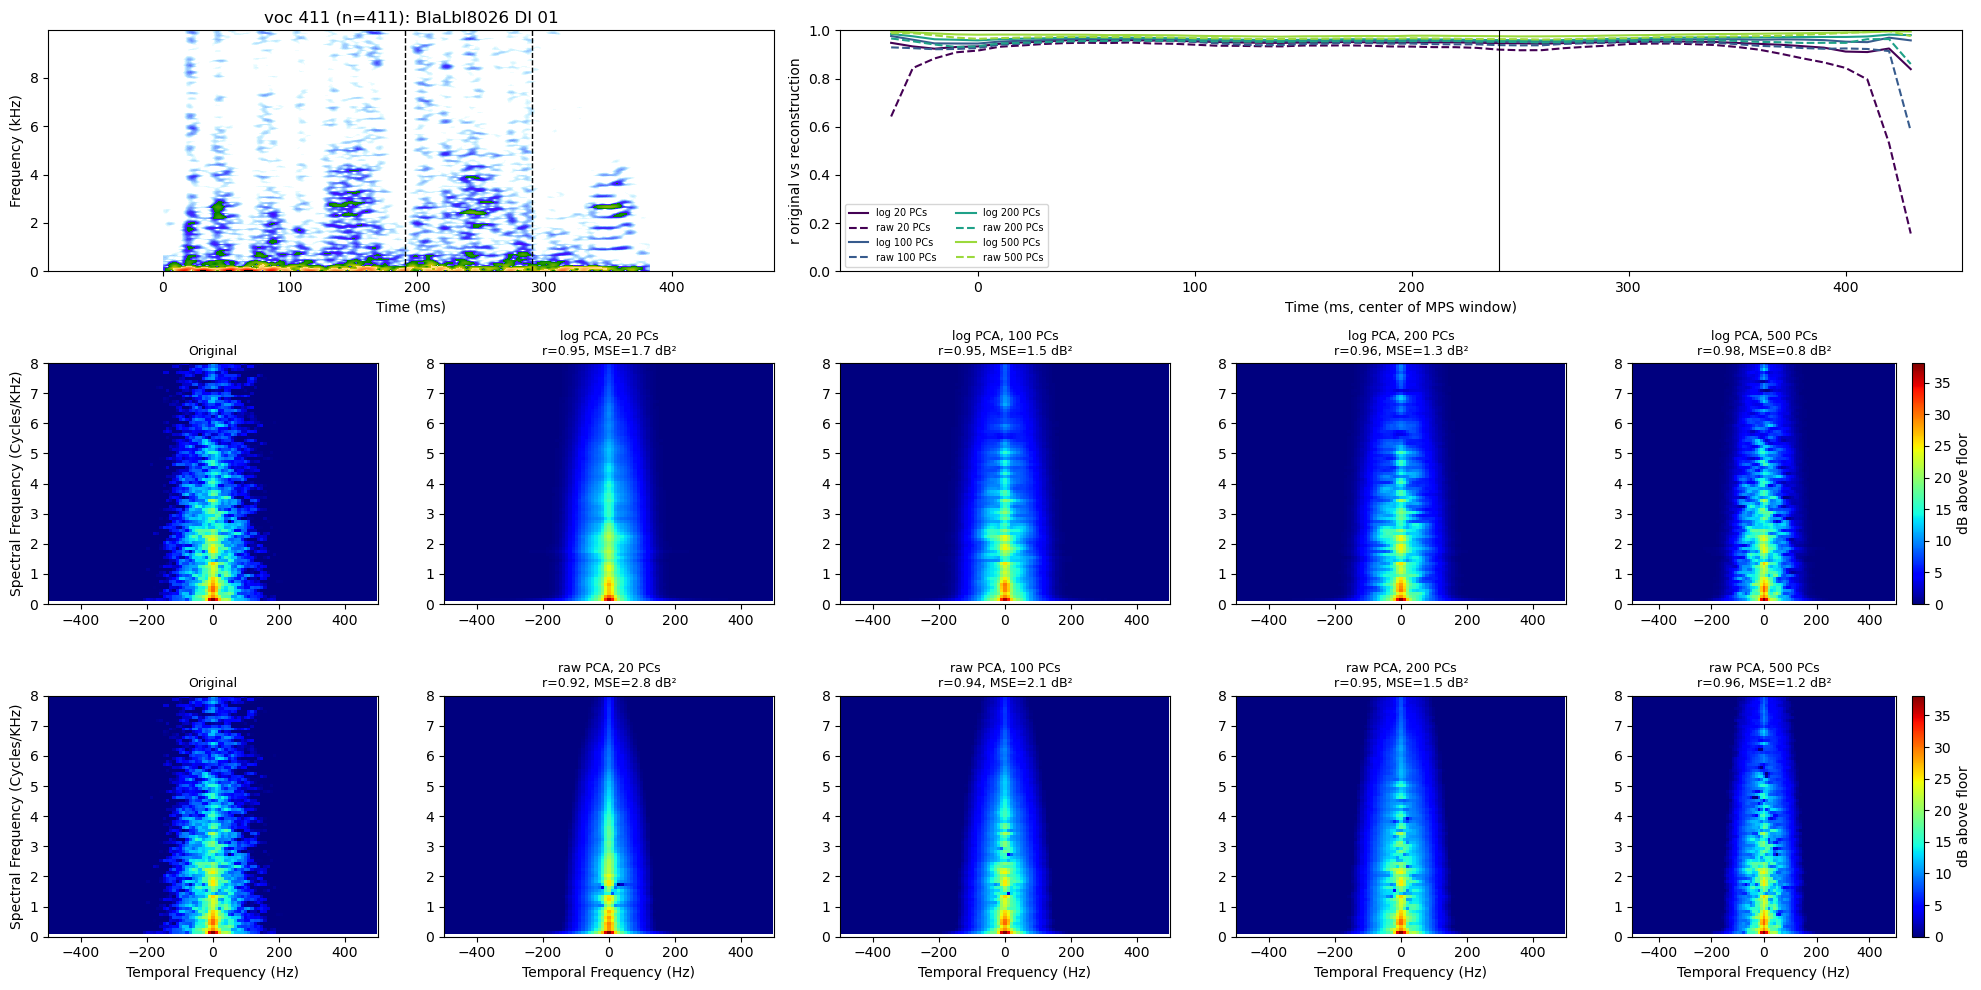

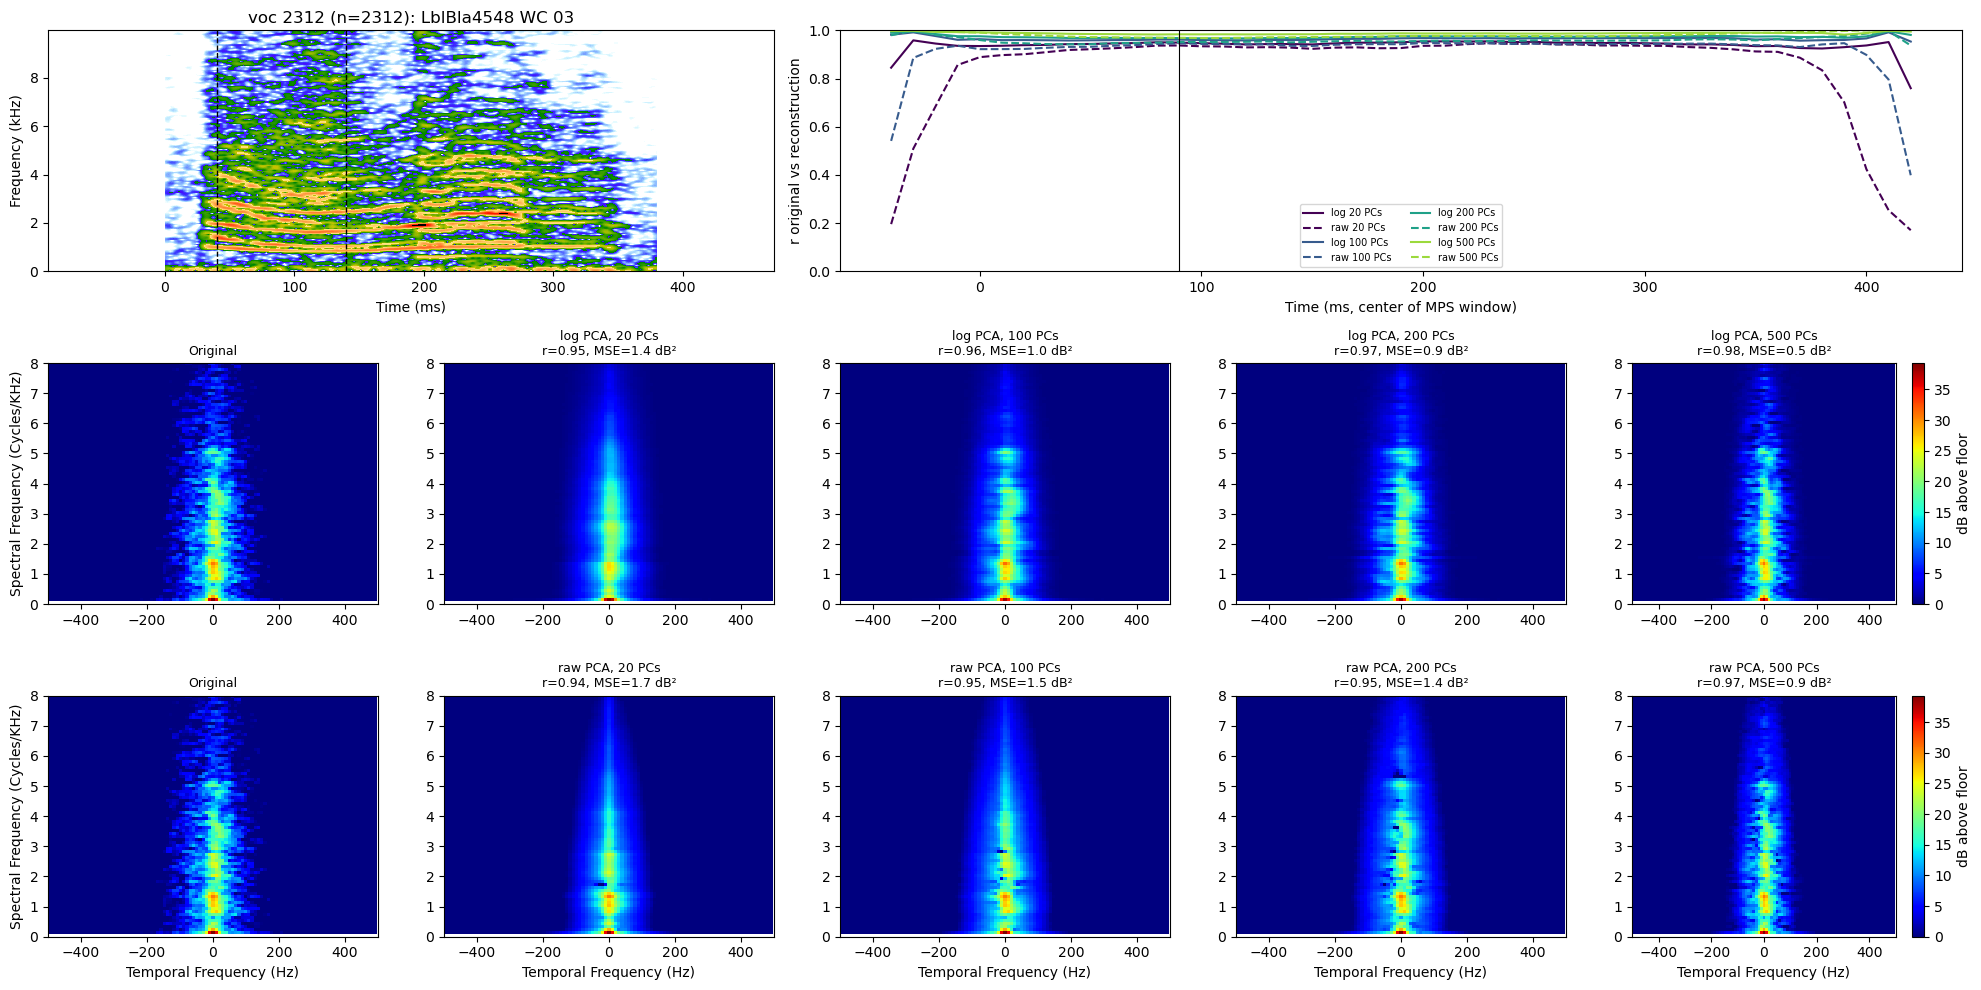

In [ ]:
K_EX = 200                      # number of PCs used to pick the median example
KS_EX = (20, 100, 200, 500)    # numbers of PCs shown in the example reconstructions
WT_LIM = 500                   # temporal modulation range shown (Hz)
WF_LIM = 8                     # spectral modulation range shown (cycles/kHz)
DBNOISE = 50                   # dynamic range of the spectrogram display (dB)
for ct in CALLTYPES:
    plot_reconstruction_example(example_idx[ct])

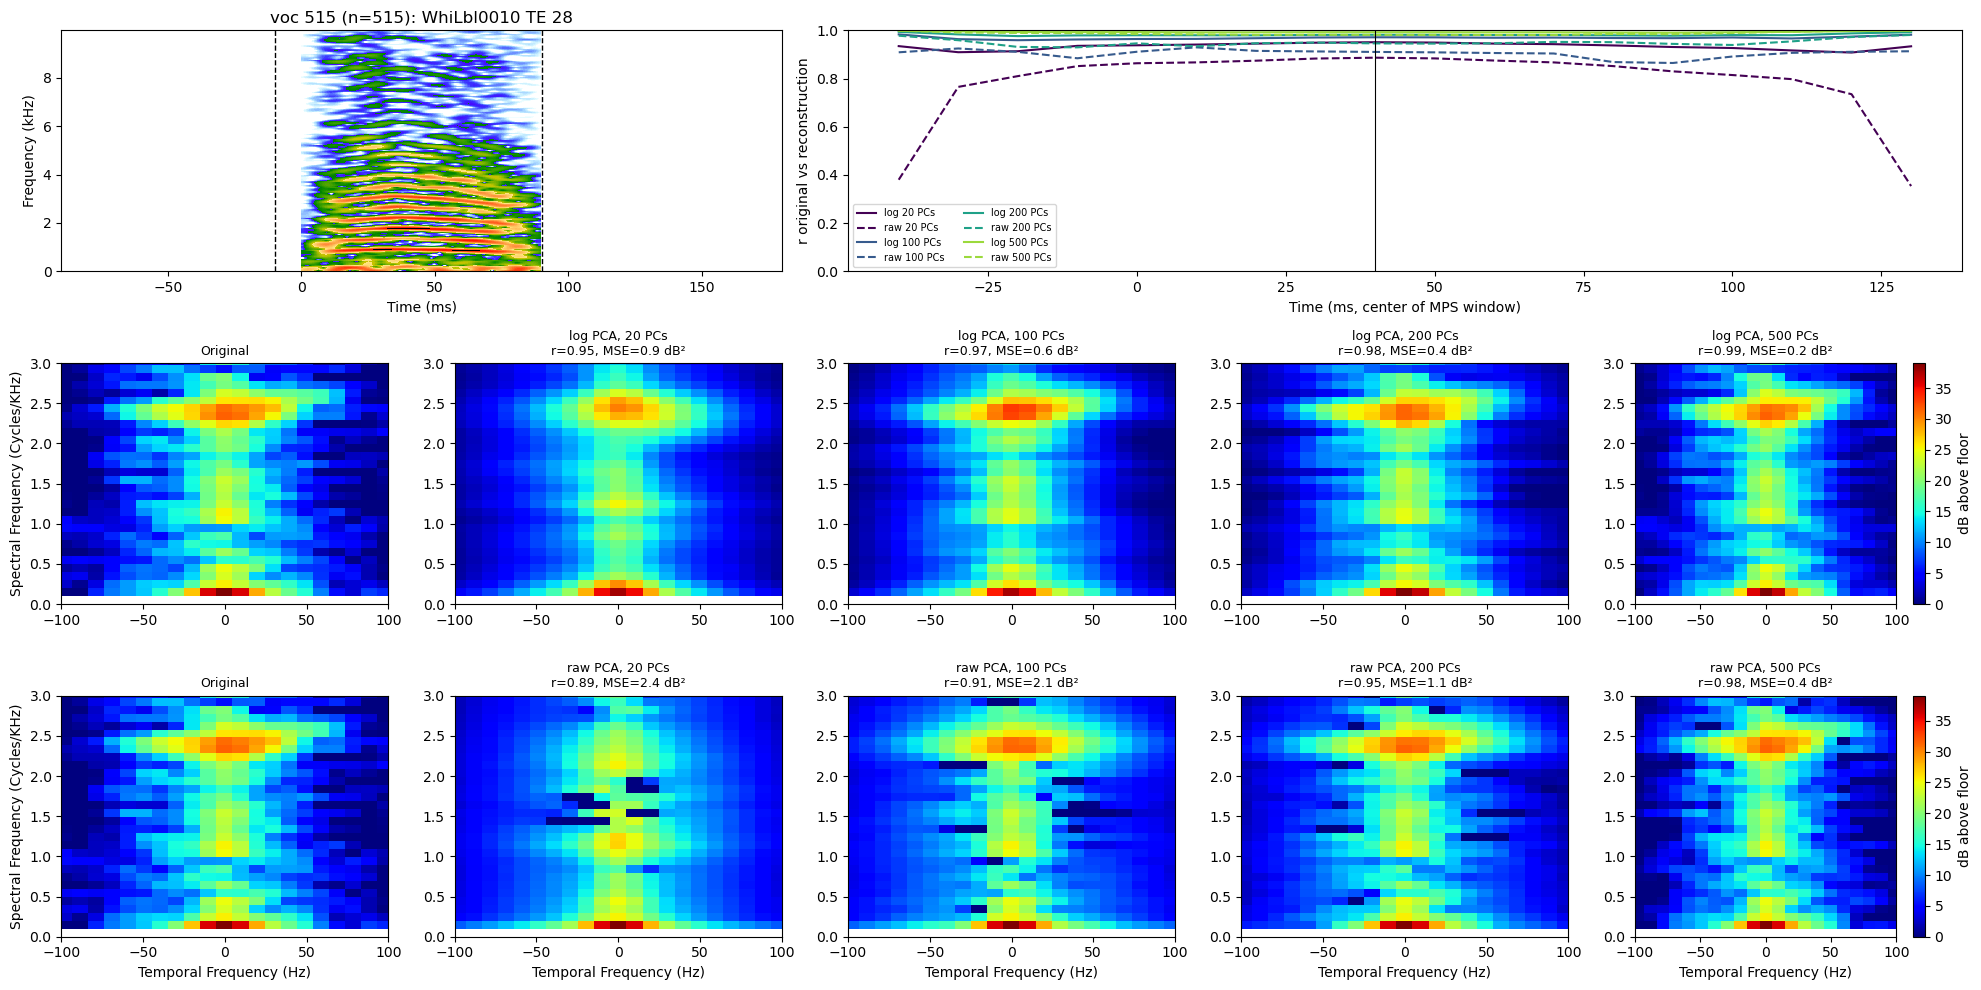

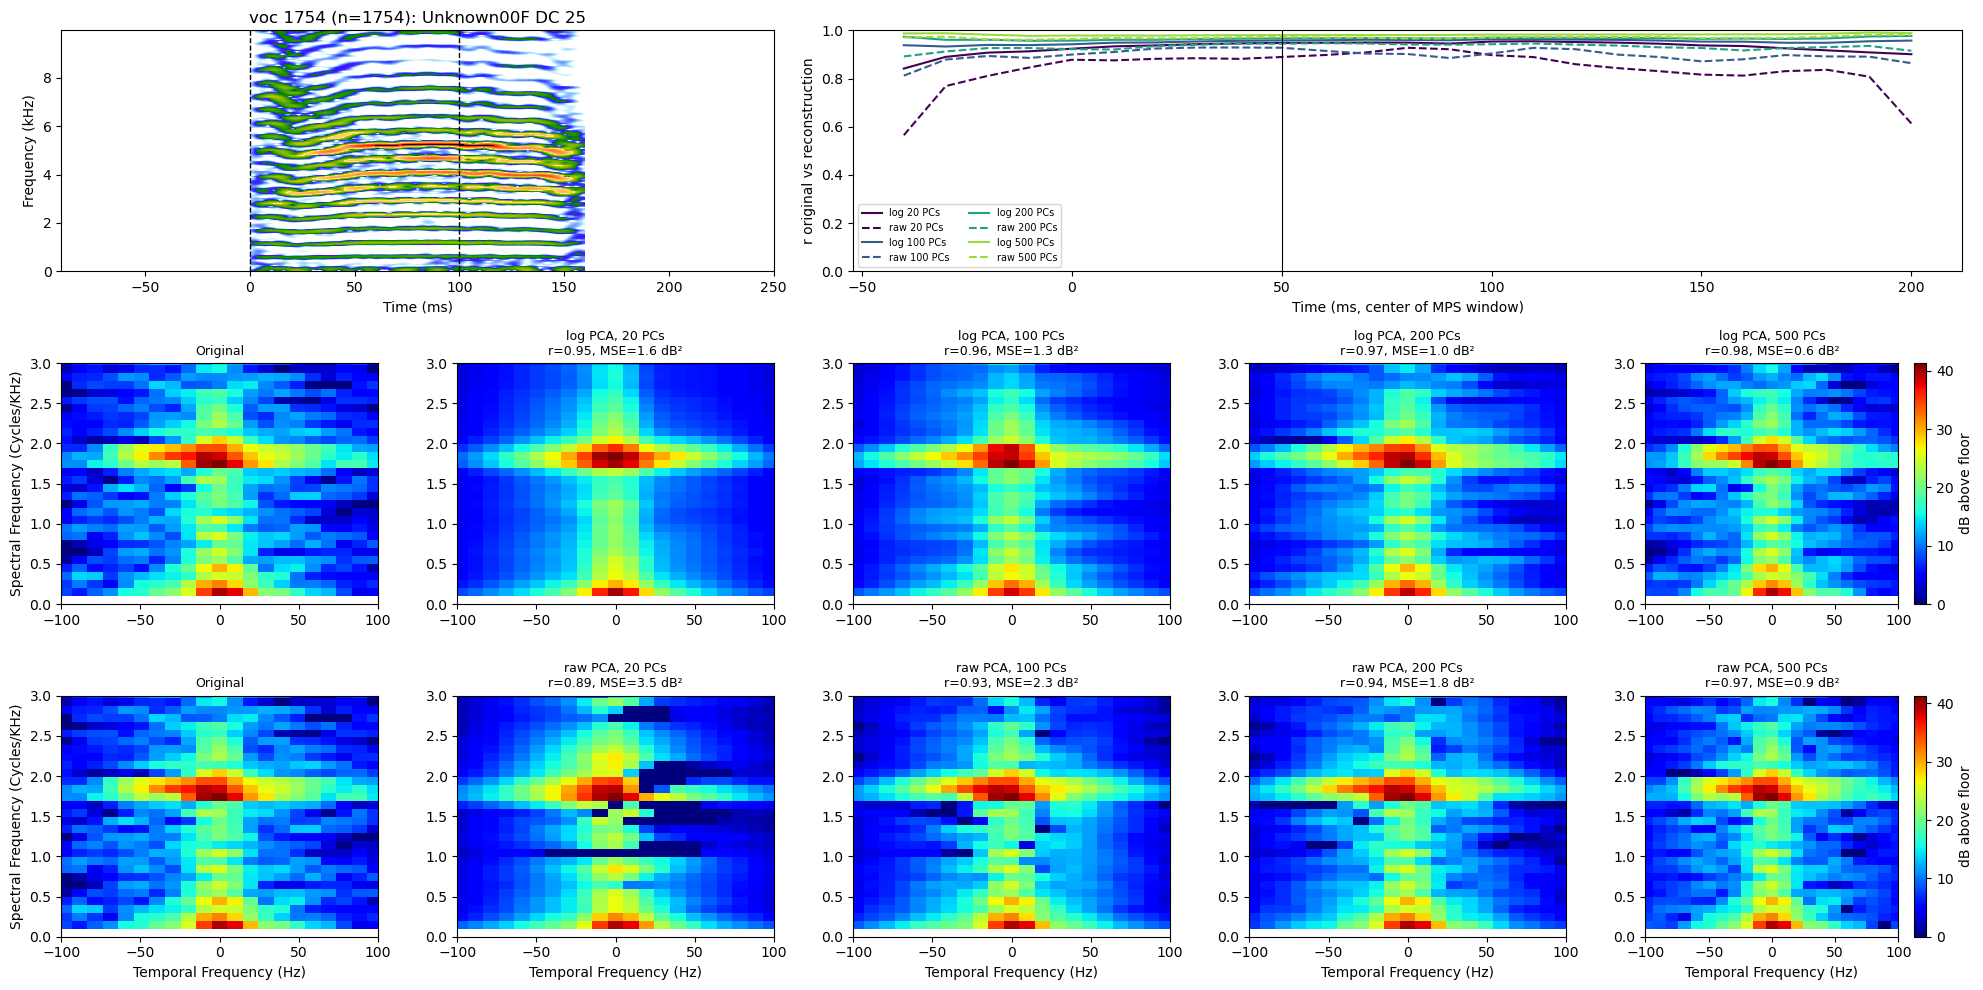

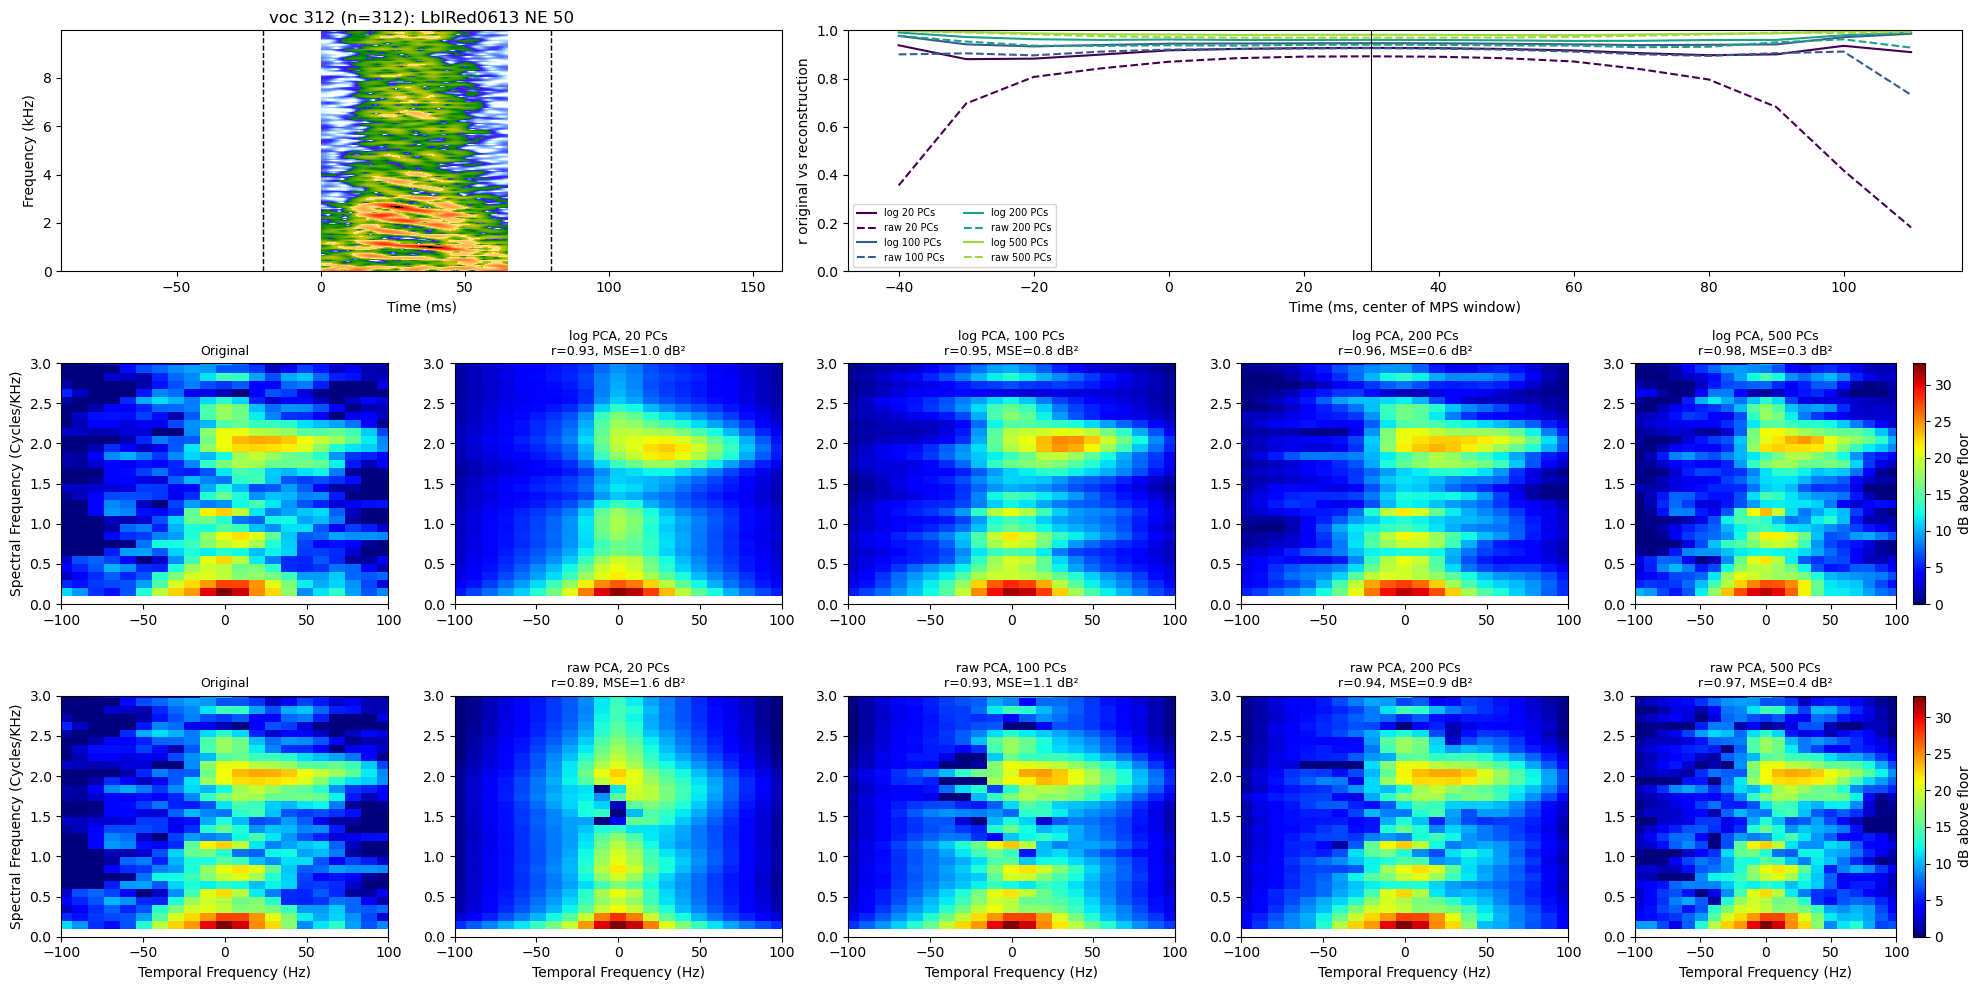

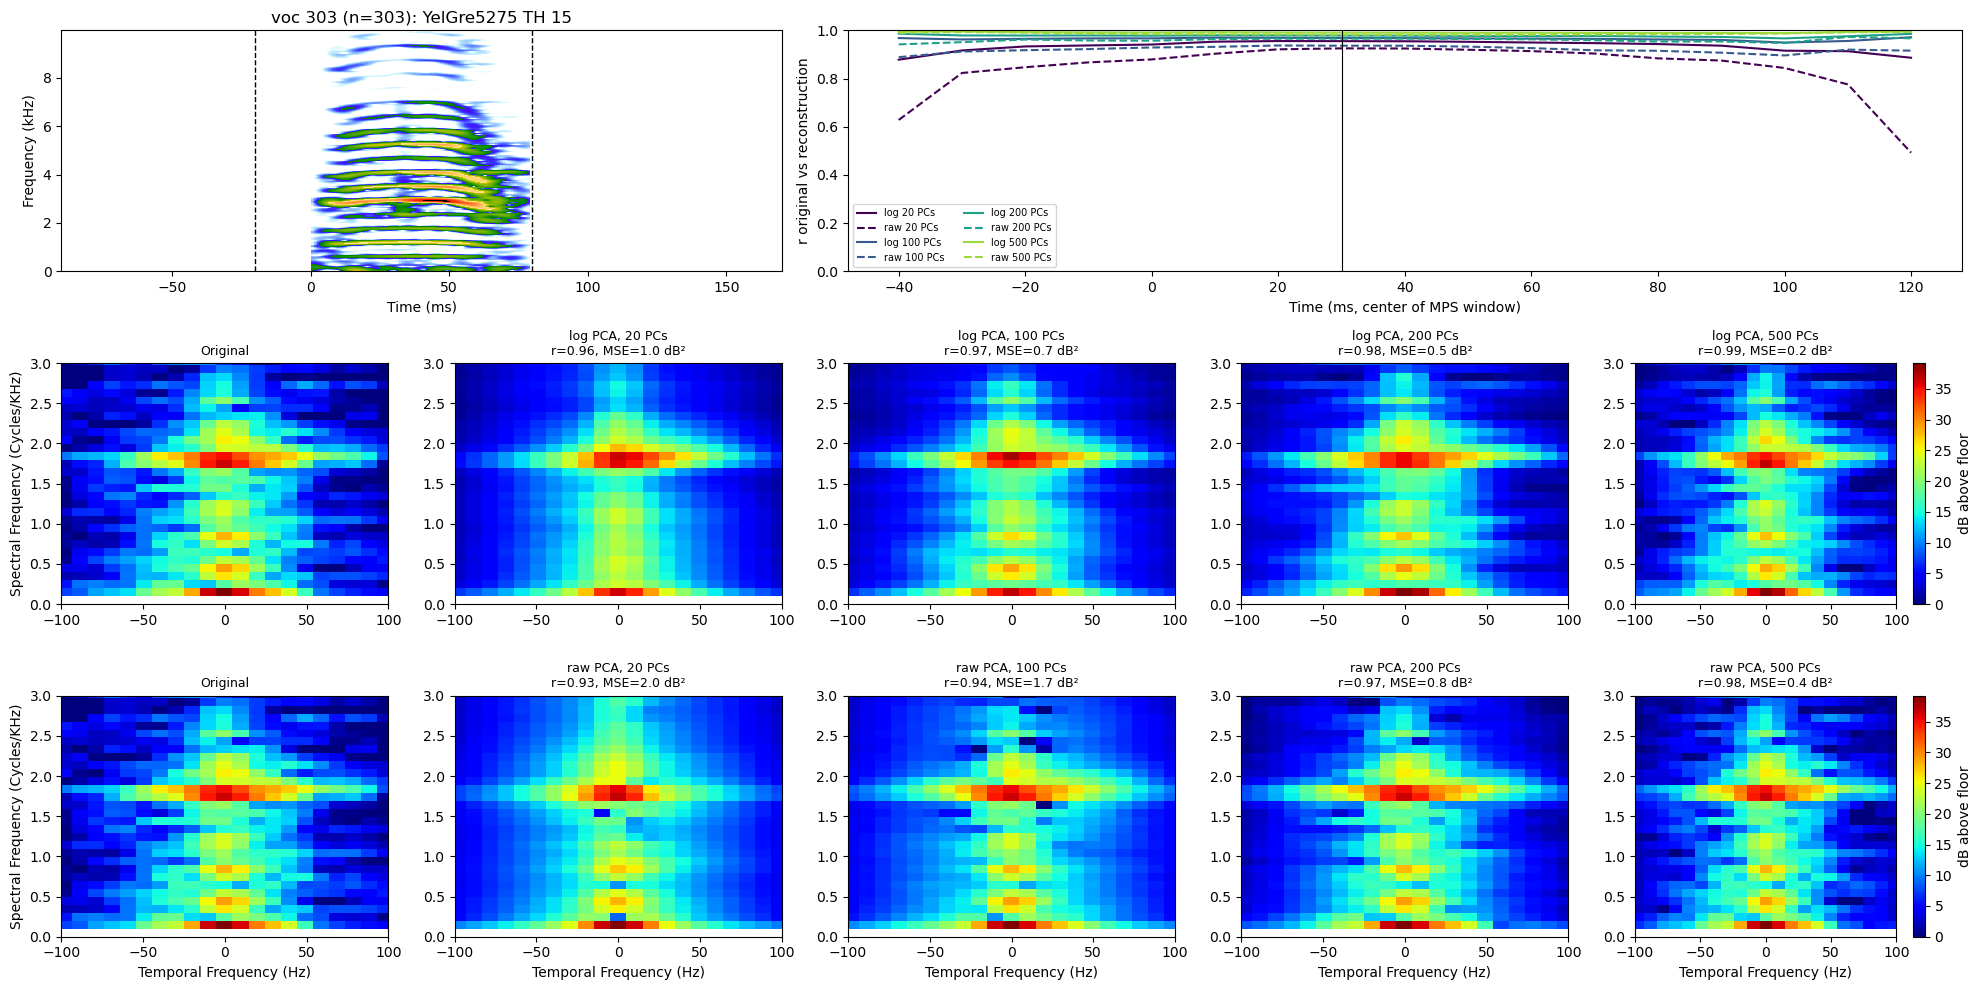

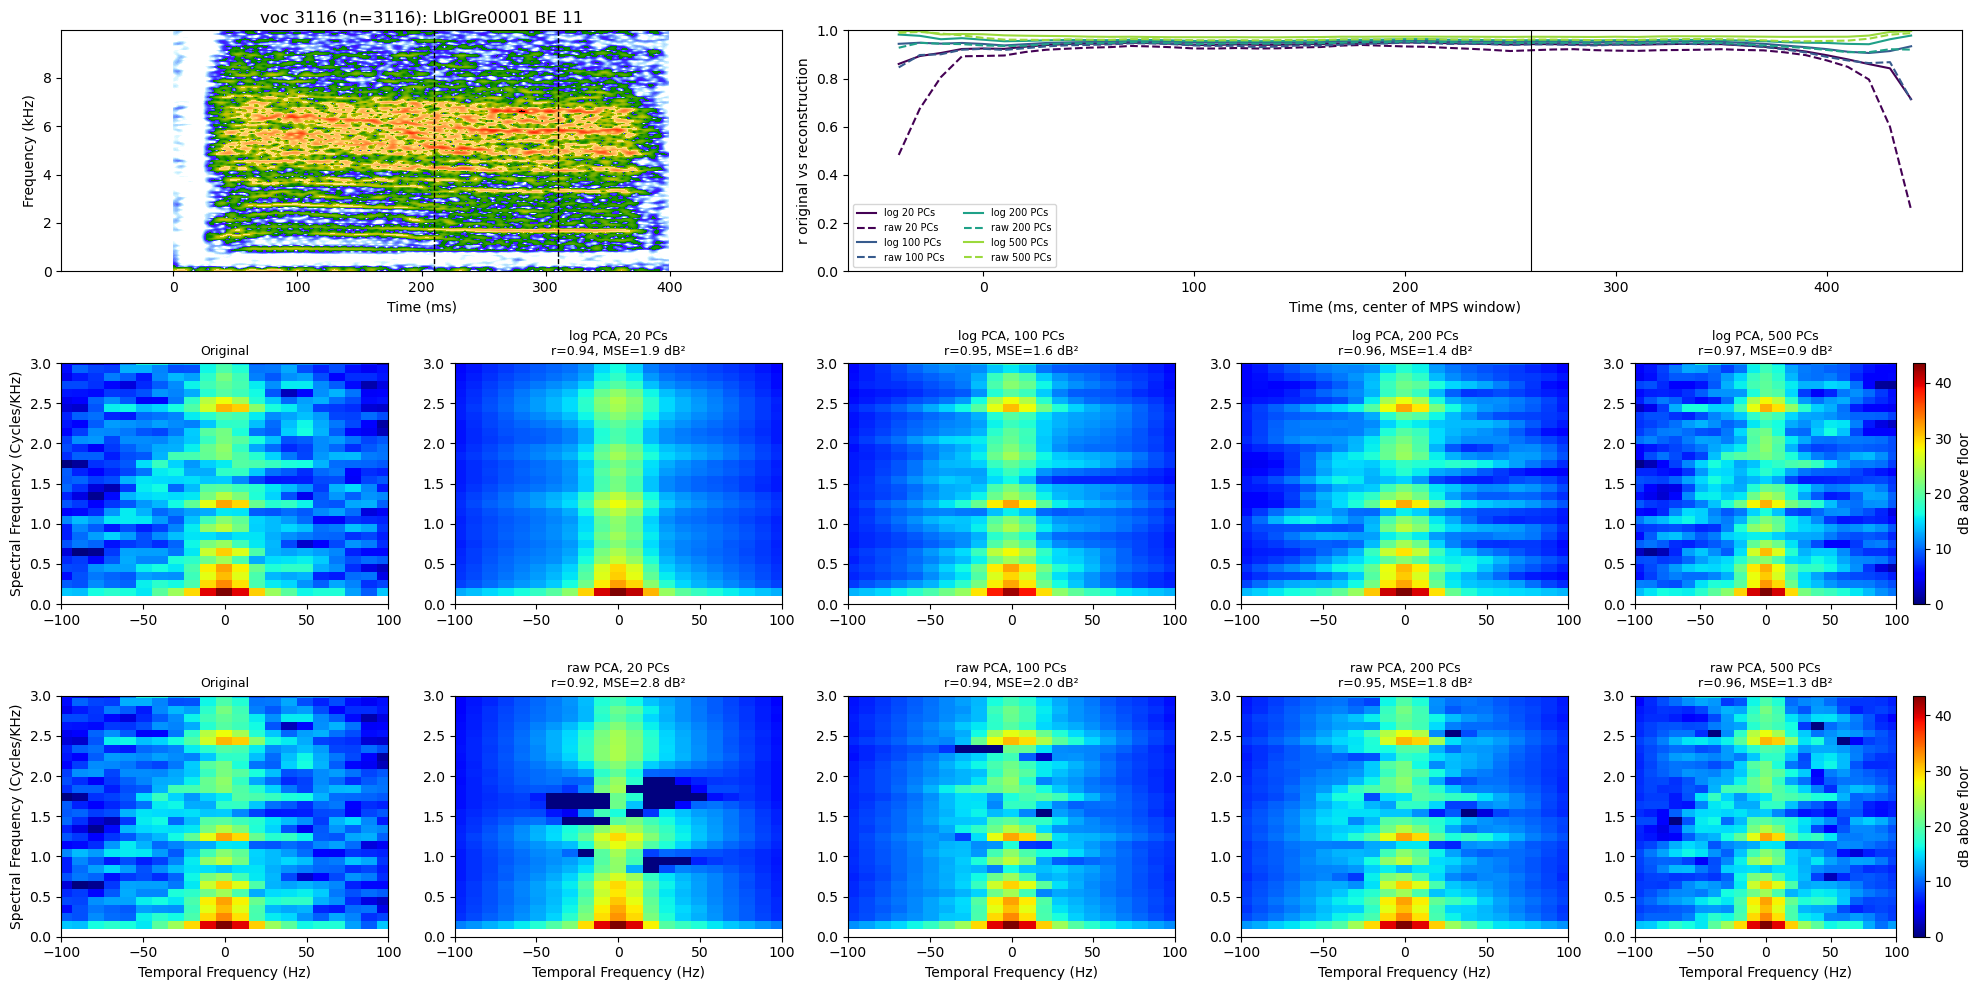

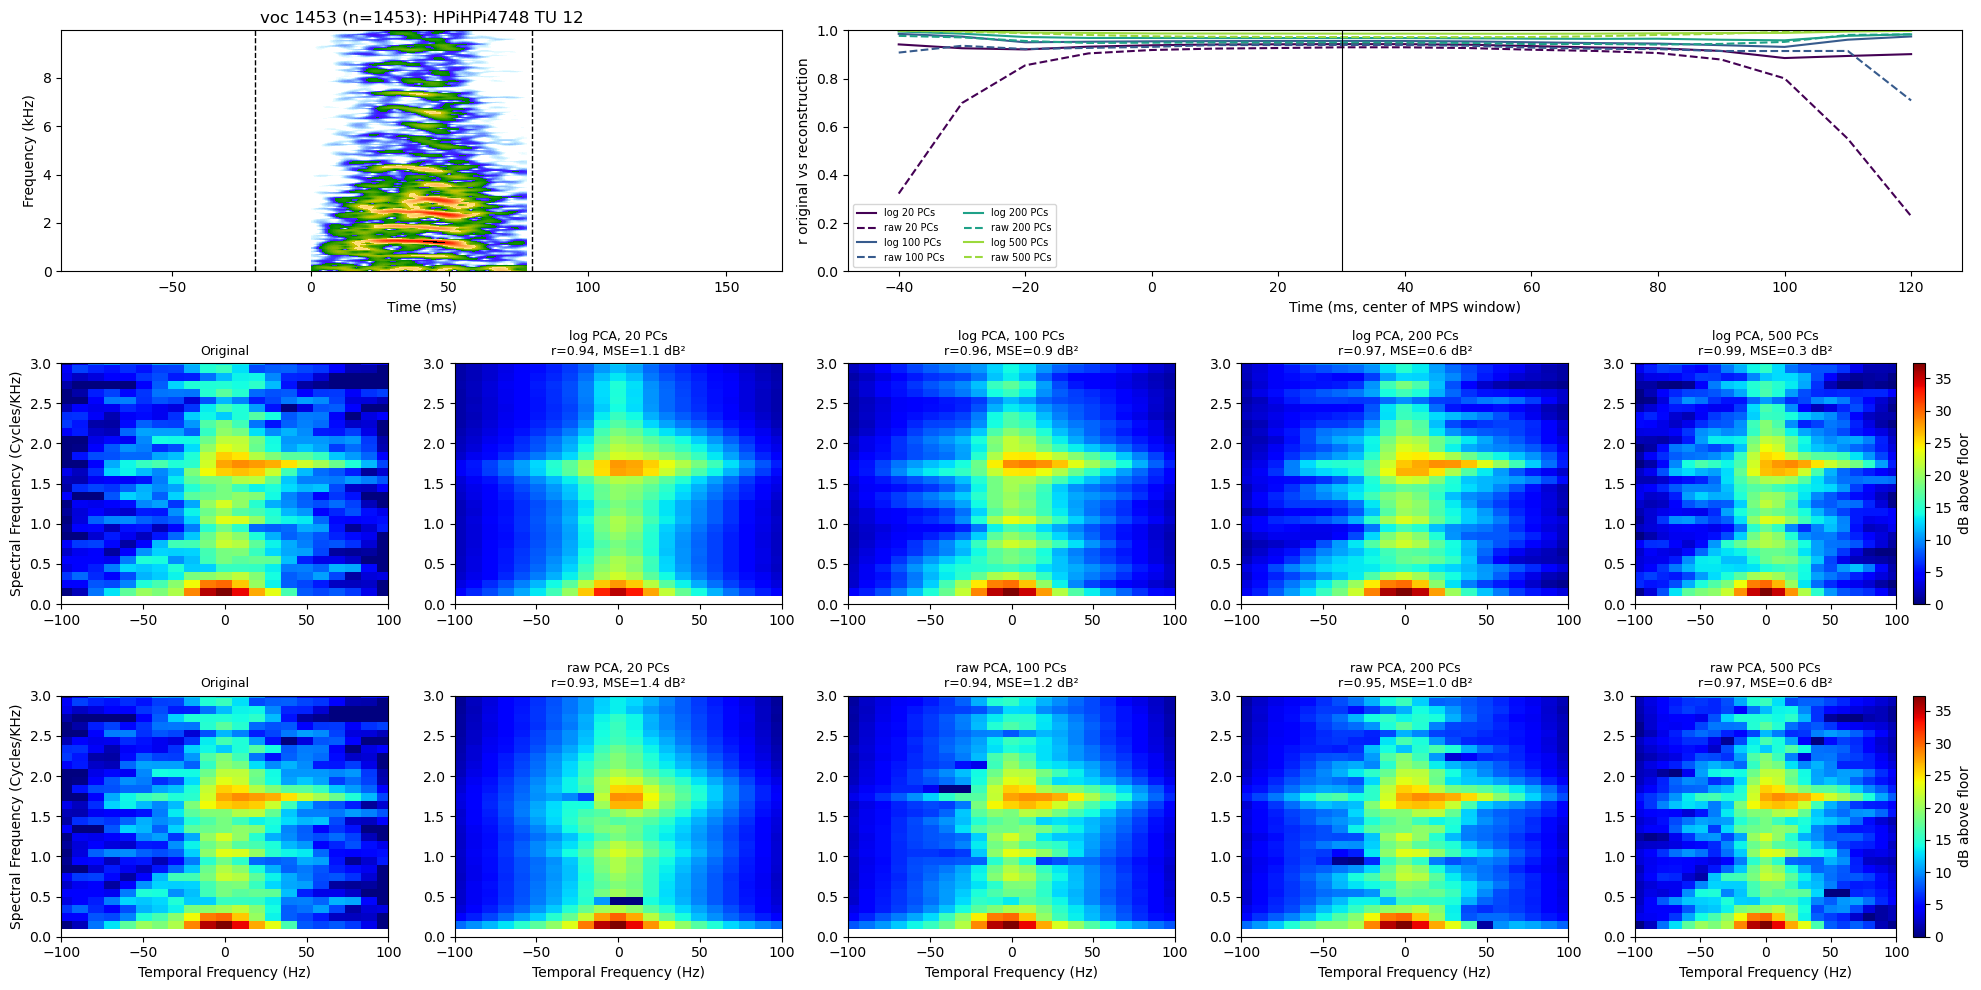

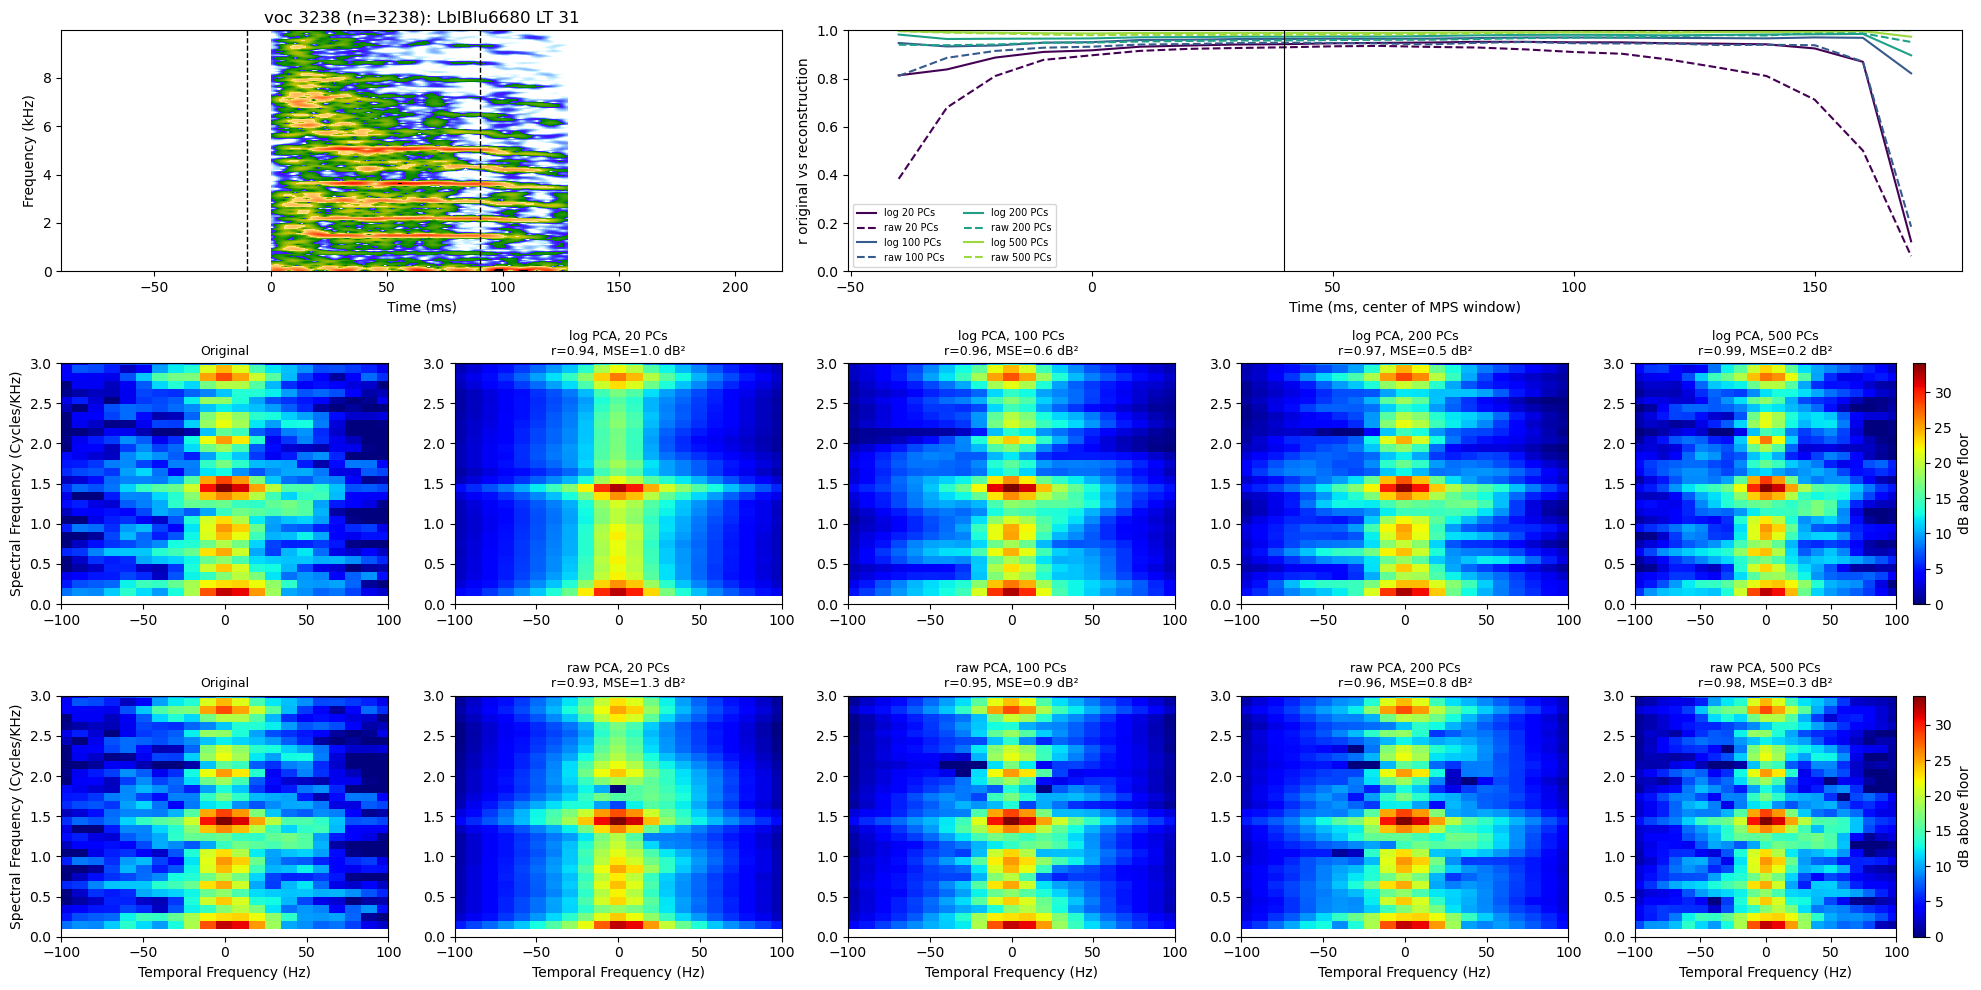

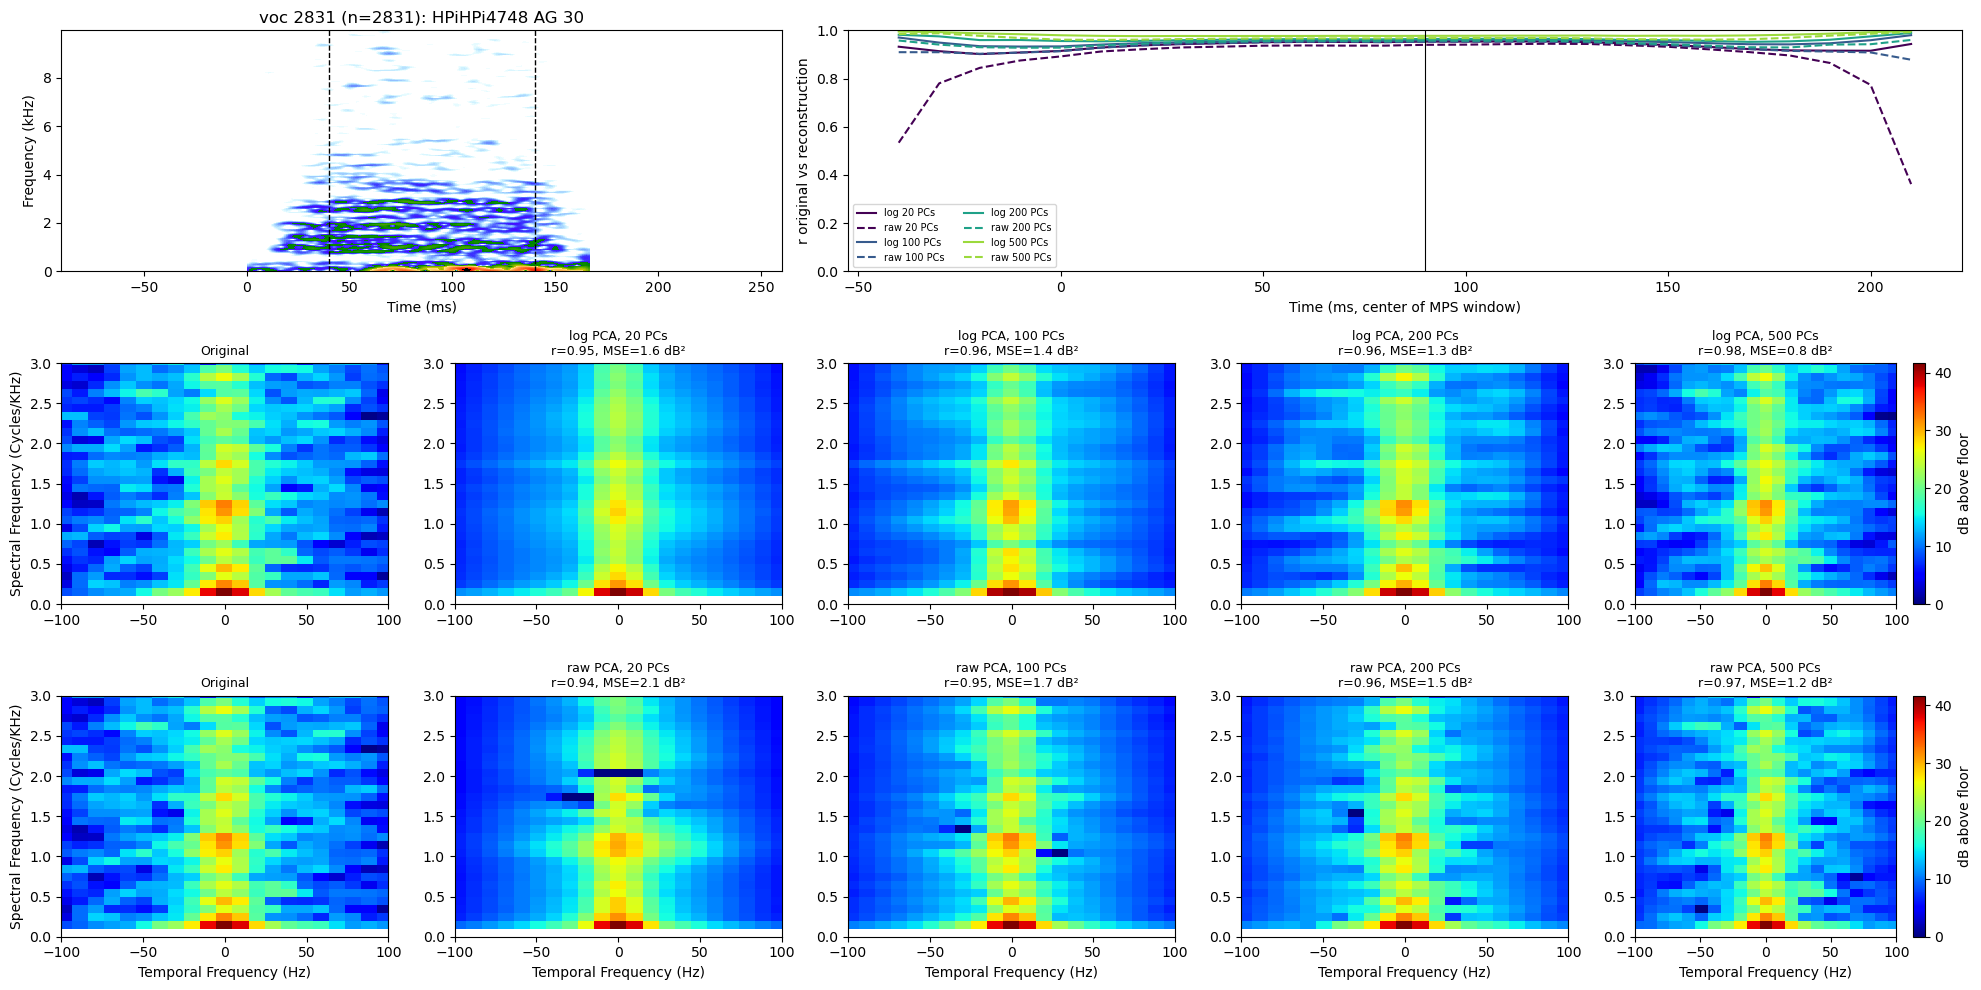

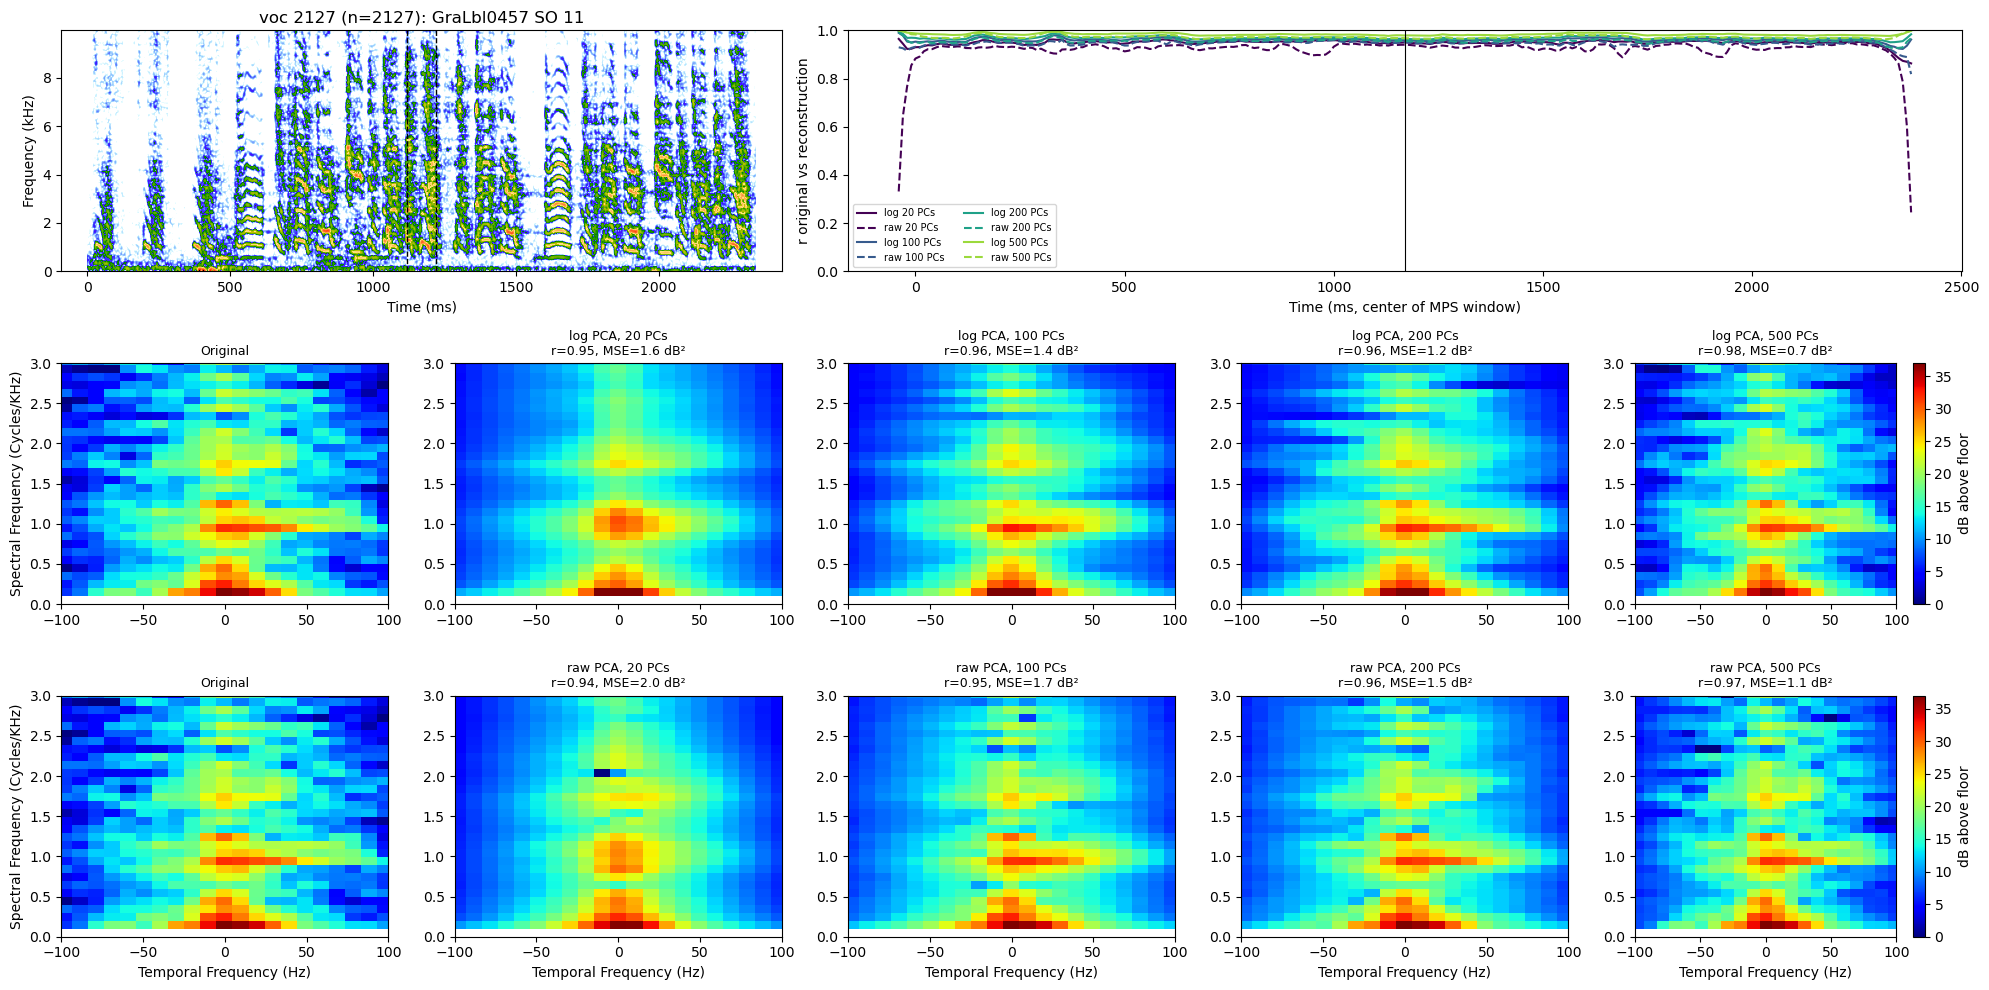

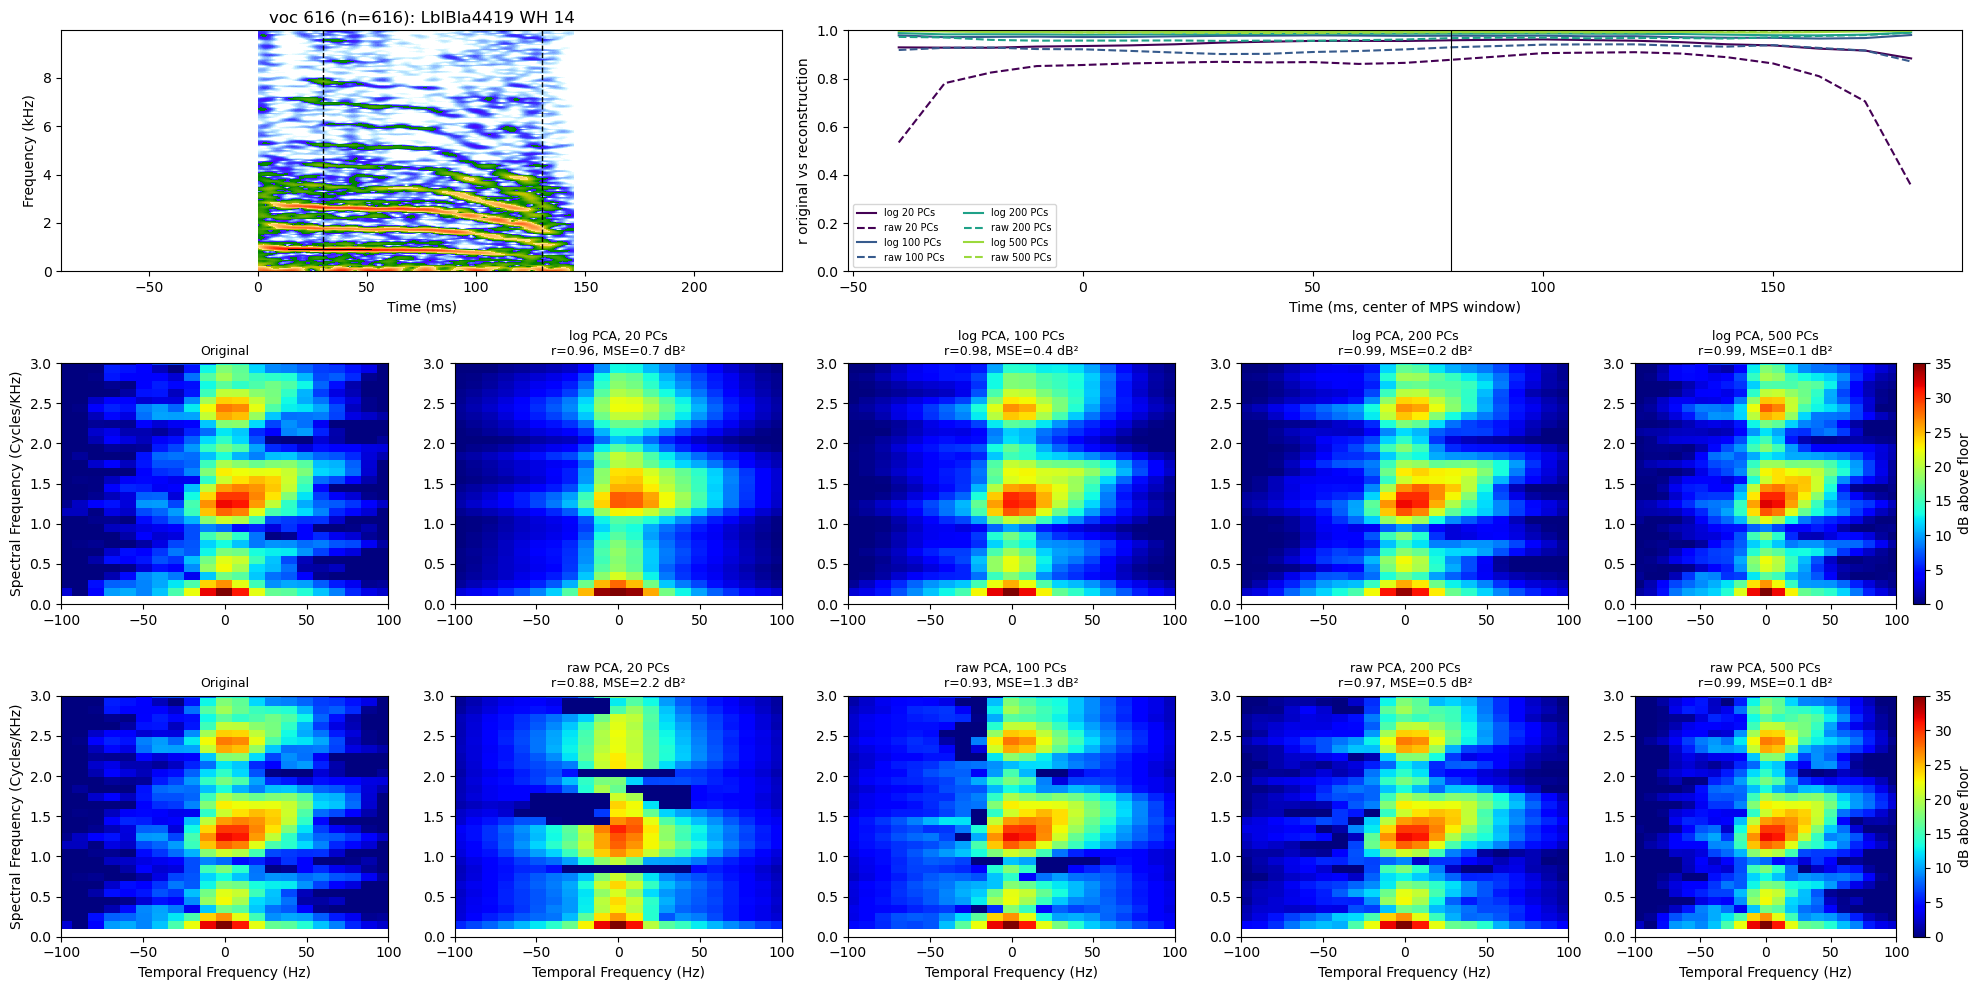

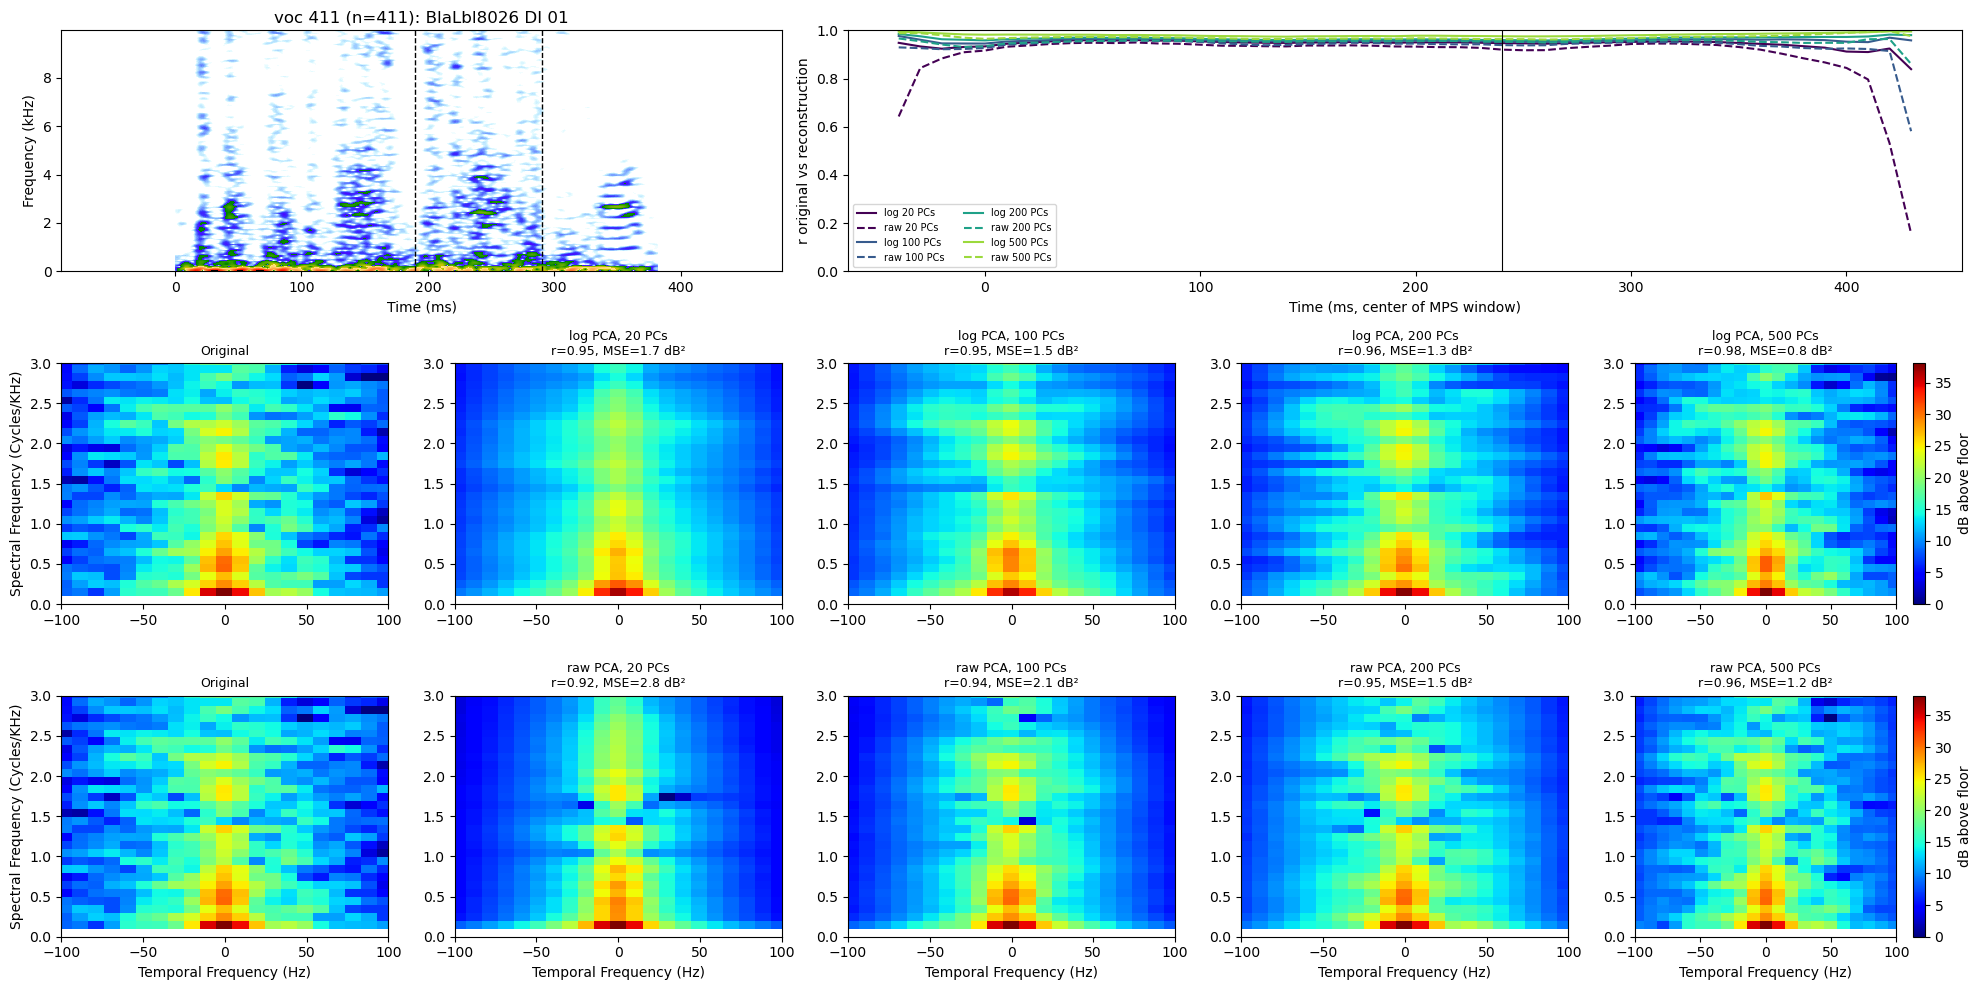

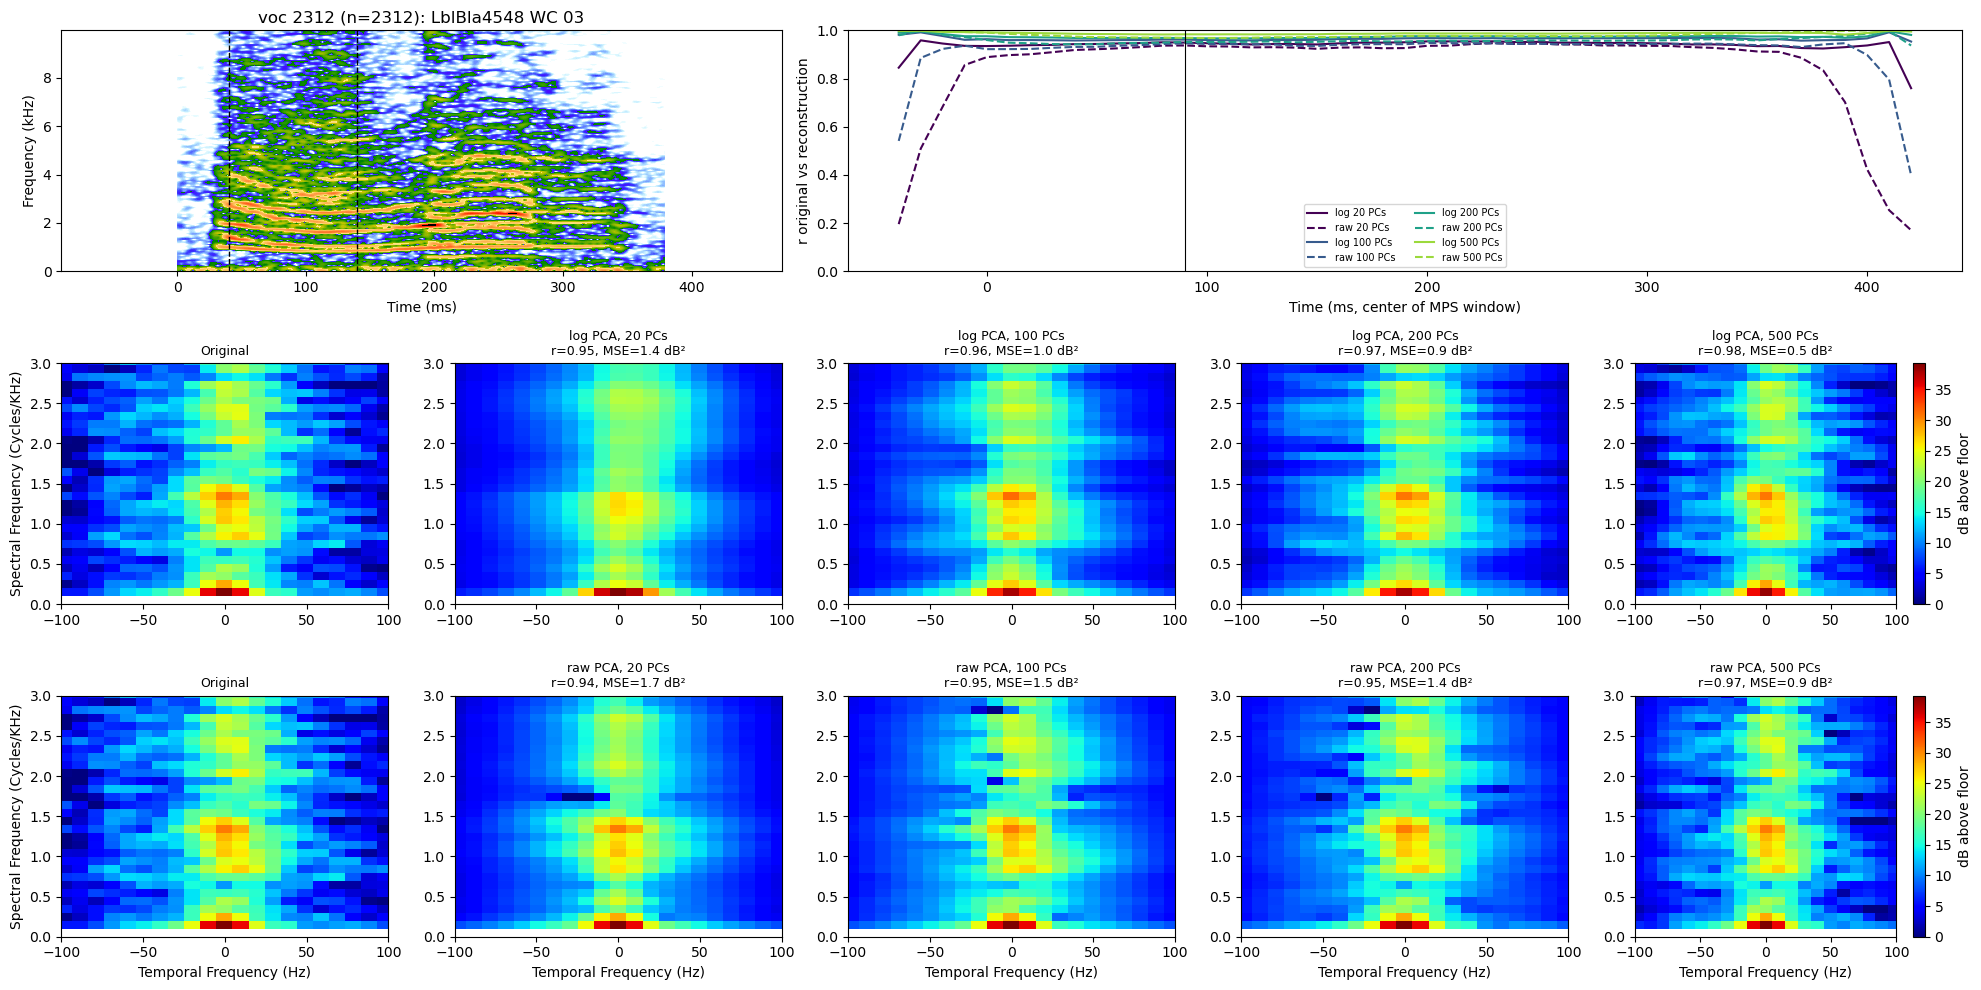

In [19]:
K_EX = 200                      # number of PCs used to pick the median example
KS_EX = (20, 100, 200, 500)    # numbers of PCs shown in the example reconstructions
WT_LIM = 100                   # temporal modulation range shown (Hz)
WF_LIM = 3                     # spectral modulation range shown (cycles/kHz)
DBNOISE = 50                   # dynamic range of the spectrogram display (dB)
for ct in CALLTYPES:
    plot_reconstruction_example(example_idx[ct])

## Summary (run of 2026-11-03, 3433 vocalizations, 173649 non-silent windows)
- **The log PCA reconstructs the log tMPS better than the raw PCA at every number of PCs.** Overall R²: log 0.63 / 0.68 / 0.73 / 0.79 / 0.89 vs raw 0.30 / 0.41 / 0.56 / 0.67 / 0.82 for 20 / 50 / 100 / 200 / 500 PCs. The raw PCA needs about 200 PCs to reach the R² of the log PCA with 50 PCs.
- The raw PCA explains 97% of the variance **in power** with 20 PCs but only 30% **in dB**: power variance is concentrated in the few high-energy, low-modulation bins, so the raw PCs spend their dimensions there. At low numbers of PCs, raw-PCA reconstructions also have negative power in some bins, which shows up as holes at the floor in the example MPSs.
- The **shape** of each window's MPS is well captured by both (mean per-window r ≥ 0.87 for raw and ≥ 0.94 for log with 20 PCs), so most of the dB error is in the fine structure rather than the overall shape. Windows at the onset and offset of a vocalization (overlapping the zero padding) are the worst reconstructed, especially by the raw PCA.
- **Call types** (log PCA, 50 PCs): best recovered are WH (R² 0.87), TE (0.82), LT (0.81), NE (0.77) and TH (0.77); worst are BE and SO (0.61), AG (0.66), DI (0.66) and DC (0.68). The ranking is similar for the raw PCA, except that DC is the worst call type for the raw PCA at low numbers of PCs (R² 0.19 with 20 PCs). DI (n=20) and WC (n=3) have too few vocalizations to be compared reliably.
- Caveats: reconstructions are in-sample (the PCAs were fitted on all these vocalizations), and R² is relative to the dataset-mean MPS, so call types whose MPS differs more from the average one can reach a higher R² for the same error in dB.